# 03 · Análisis y visualización — Precios y promociones en Abarrotes (Plaza Vea)

**Entrada:** `data/processed/productos_plazavea_final.csv` (dataset analítico generado en `02_preprocessing.ipynb`: 1437 productos).

**Objetivo general (Parte I, actualizado):** analizar la distribución de precios y el comportamiento de los descuentos **observables** entre marcas y categorías de Abarrotes de Plaza Vea, para identificar patrones promocionales y diferencias en los precios publicados.

**Usuario de los resultados:** un analista que monitorea precios y promociones publicados en el canal web (seguimiento descriptivo de la oferta). Las recomendaciones se formulan para ese usuario.

Cada sección responde una pregunta explícita:

| Sección | Pregunta |
|---|---|
| A | ¿Cómo se distribuyen los precios actuales, cómo varían entre grupos y cuánto varían dentro de una subcategoría una vez normalizados por contenido? |
| B | ¿Con qué frecuencia aparecen productos con rebaja, globalmente, por grupo de categoría y por marca? ¿Es sensible la tasa a los registros imputados? |
| C | ¿Qué tan profundos son los descuentos entre los productos promocionados? |
| D | ¿Qué marcas concentran los productos extraídos y cómo se comporta BELL'S, la marca con más productos? |
| E | ¿Qué grupos y subcategorías muestran mayor intensidad promocional observable? |
| F | ¿Qué relaciones descriptivas existen entre precio, presencia y profundidad de rebaja, y cómo se comportan los packs? |
| G | ¿Qué casos anómalos o extremos merecen revisión? |

> **Alcance.** Snapshot de una fecha de extracción, 30 de ~65 páginas del listado en su orden de aparición (muestra no aleatoria, no censo), solo Abarrotes. La composición por categoría y marca depende de ese orden. Los resultados describen **precios y promociones publicados en la muestra extraída**; no miden ventas, demanda, márgenes, competitividad ni causalidad. Los intervalos de confianza y las pruebas estadísticas se reportan como evidencia descriptiva de que una diferencia no es atribuible solo a la variabilidad de muestras pequeñas; como la muestra no es aleatoria, no permiten generalizar al catálogo completo.

> **Convención de figuras.** La numeración es la misma del informe final (Figura 1 = diagrama del pipeline; Figuras 2–12 en el cuerpo; Figuras A1–A8 en el Anexo A) y se registra en `reports/metrics.json`.

## 0. Configuración y carga

In [1]:
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display

DATA = Path("../data/processed/productos_plazavea_final.csv")
FIG_DIR = Path("../reports/figures")
TAB_DIR = Path("../reports/tables")
REP_DIR = Path("../reports")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Paleta sobria (la misma del notebook 02)
AZUL, ROJO, GRIS, GRIS_CLARO = "#2F5D7C", "#C8553D", "#8C8C8C", "#D9D9D9"
ORDEN_INT = ["Sin descuento", "Bajo", "Medio", "Alto"]
COLORES_INT = {"Sin descuento": GRIS_CLARO, "Bajo": "#A6C8DD", "Medio": "#4F86AE", "Alto": "#1F3F57"}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Métricas del preprocesamiento (límites IQR, conteos, figuras del notebook 02)
with open(REP_DIR / "metrics_preprocesamiento.json", encoding="utf-8") as f:
    PRE = json.load(f)

# ---------- Numeración de figuras: la misma del informe final (docs/informe_final.pdf) ----------
# Figura 1 del informe = reports/figures/pipeline.png (generada por scripts/diagrama_pipeline.py, no por un notebook).
# Cuerpo del informe: Figuras 2–12. Anexo A del informe: Figuras A1–A8.
FIG_CUERPO = {
    "fig01_valores_faltantes.png": 2,            # 02 · Preprocesamiento (6.3)
    "fig02_distribucion_precio_actual.png": 3,   # A
    "fig03_precio_por_category_group.png": 4,    # A
    "fig04_precio_unitario_subcategoria.png": 5, # A
    "fig05_promo_rate_category_group.png": 6,    # B
    "fig06_promo_rate_marcas.png": 7,            # B / D
    "fig07_distribucion_descuento.png": 8,       # C
    "fig10_intensidad_por_category_group.png": 9,  # E
    "fig11_promo_rate_subcategorias.png": 10,    # E
    "fig13_precio_vs_descuento.png": 11,         # F
    "fig14_packs_abarrotes_vs_resto.png": 12,    # F
}
FIG_ANEXO = {
    "figA1_outliers_precio_actual.png": "A1",    # 02 · Outliers (detalle)
    "figA2_outliers_precio_regular.png": "A2",   # 02
    "figA3_outliers_descuento_pct.png": "A3",    # 02
    "figA4_top_marcas_productos.png": "A4",      # D
    "figA5_regular_vs_actual.png": "A5",         # F · validación
    "fig08_intensidad_promocional.png": "A6",    # C
    "fig09_descuento_por_category_group.png": "A7",  # E
    "fig12_precio_con_vs_sin_rebaja.png": "A8",  # F
}

def info_fig(nombre):
    # Número, etiqueta y ubicación de una figura según el informe final
    if nombre in FIG_CUERPO:
        n = FIG_CUERPO[nombre]
        return n, f"Figura {n}", "cuerpo"
    n = FIG_ANEXO[nombre]
    return n, f"Figura {n}", "anexo A"

FIGURAS = {}
def guardar_fig(fig, nombre, titulo, seccion, pregunta, hallazgo, n=None):
    # Guarda la figura (PNG, 200 dpi) y registra sus metadatos con la numeración definitiva
    fig.savefig(FIG_DIR / nombre, dpi=200, bbox_inches="tight", facecolor="white")
    num, etiqueta, ubic = info_fig(nombre)
    FIGURAS[nombre] = {"numero": num, "etiqueta": etiqueta, "titulo": titulo, "titulo_completo": f"{etiqueta}. {titulo}",
                       "ubicacion": ubic, "archivo": f"reports/figures/{nombre}", "notebook": "03_analysis.ipynb",
                       "seccion": seccion, "pregunta": pregunta, "hallazgo_cifra": hallazgo, "n": n}
    print(f"{etiqueta} guardada: reports/figures/{nombre}")

# ---------- Formato numérico en español ----------
def nf(x, d=1):
    # Número con coma decimal: nf(7.9, 2) -> "7,90"
    return f"{x:.{d}f}".replace(".", ",")

def ejes_coma(ax, ejes="xy"):
    # Coma decimal en las etiquetas numéricas de los ejes indicados
    fmt = FuncFormatter(lambda v, p: f"{v:g}".replace(".", ","))
    for e in ejes:
        getattr(ax, f"{e}axis").set_major_formatter(fmt)

TICKS_LOG = [1, 2, 5, 10, 20, 50, 100]
def ejes_log_legibles(ax, eje="x", ticks=TICKS_LOG, lim=(0.7, 115)):
    # Escala logarítmica con etiquetas legibles (1, 2, 5, 10, ...)
    for e in eje:
        getattr(ax, f"set_{e}scale")("log")
        getattr(ax, f"set_{e}ticks")(ticks)
        getattr(ax, f"set_{e}ticklabels")([f"{t:g}".replace(".", ",") for t in ticks])
        getattr(ax, f"set_{e}lim")(*lim)

def r2(x):
    # Redondeo a 2 decimales como float nativo (mismo criterio que DataFrame.round)
    return float(np.round(float(x), 2))

def fmt_p(p):
    # p-valor legible con coma decimal
    return "p < 0,001" if p < 0.001 else f"p = {nf(p, 3)}"

# ---------- Estadística descriptiva para proporciones ----------
def wilson(k, n, z=1.96):
    # Intervalo de confianza de Wilson al 95 % para una proporción k/n (en %)
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z ** 2 / n
    centro = (p + z ** 2 / (2 * n)) / den
    margen = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return (100 * (centro - margen), 100 * (centro + margen))

def agregar_wilson(tabla, k="n_promo", n="n"):
    ic = [wilson(a, b) for a, b in zip(tabla[k], tabla[n])]
    tabla["ic95_inf"] = [round(i[0], 1) for i in ic]
    tabla["ic95_sup"] = [round(i[1], 1) for i in ic]
    return tabla

def chi2_2x2(a, b, c, d):
    # Chi-cuadrado de Pearson (sin corrección de Yates) para [[a, b], [c, d]]; p-valor con 1 g.l.
    n = a + b + c + d
    chi2 = n * (a * d - b * c) ** 2 / ((a + b) * (c + d) * (a + c) * (b + d))
    return chi2, math.erfc(math.sqrt(chi2 / 2))

def fisher_2x2(a, b, c, d):
    # Prueba exacta de Fisher bilateral para [[a, b], [c, d]] (hipergeométrica en escala log)
    r1, c1, n = a + b, a + c, a + b + c + d
    def logp(x):
        return (math.lgamma(r1 + 1) - math.lgamma(x + 1) - math.lgamma(r1 - x + 1)
                + math.lgamma(n - r1 + 1) - math.lgamma(c1 - x + 1) - math.lgamma(n - r1 - c1 + x + 1)
                - math.lgamma(n + 1) + math.lgamma(c1 + 1) + math.lgamma(n - c1 + 1))
    lo, hi = max(0, c1 - (n - r1)), min(r1, c1)
    lp_obs = logp(a)
    return min(1.0, sum(math.exp(logp(x)) for x in range(lo, hi + 1) if logp(x) <= lp_obs + 1e-7))

def prueba_2x2(k1, n1, k2, n2):
    # Compara dos proporciones k1/n1 vs k2/n2 con chi-cuadrado y Fisher (evidencia descriptiva)
    chi2, p_chi = chi2_2x2(k1, n1 - k1, k2, n2 - k2)
    return {"k1": int(k1), "n1": int(n1), "k2": int(k2), "n2": int(n2),
            "tasa1_pct": r2(k1 / n1 * 100), "tasa2_pct": r2(k2 / n2 * 100),
            "chi2": r2(chi2), "p_chi2": float(f"{p_chi:.3g}"), "p_fisher": float(f"{fisher_2x2(k1, n1 - k1, k2, n2 - k2):.3g}")}

df = pd.read_csv(DATA, dtype={"sku": str}, encoding="utf-8")
df["promotion_intensity"] = pd.Categorical(df["promotion_intensity"], categories=ORDEN_INT, ordered=True)
promo = df[df["has_discount"] == 1].copy()   # subconjunto de productos con rebaja

M = {"dataset": {"n_productos": int(len(df)), "n_columnas": int(df.shape[1]),
                 "n_marcas": int(df["brand"].nunique()), "n_category_group": int(df["category_group"].nunique()),
                 "n_subcategorias": int(df["subcategory"].nunique()),
                 "n_promocionados": int(len(promo)), "n_sin_descuento": int((df["has_discount"] == 0).sum()),
                 "base": "Dataset analítico final (in_scope): cifras oficiales del informe"}}
print(df.shape)
print(json.dumps(M, indent=2, ensure_ascii=False))
df.head(3)

(1437, 21)
{
  "dataset": {
    "n_productos": 1437,
    "n_columnas": 21,
    "n_marcas": 271,
    "n_category_group": 12,
    "n_subcategorias": 70,
    "n_promocionados": 479,
    "n_sin_descuento": 958,
    "base": "Dataset analítico final (in_scope): cifras oficiales del informe"
  }
}


,sku,name,brand,category_level1,category_group,subcategory,presentation,presentation_imputed,content_qty,content_unit,has_multiplier,content_validated,current_price,regular_price,unit_price,has_discount,discount_amount,discount_pct,promotion_intensity,is_price_outlier,is_pack
0,10652532,Galletas Saladas FIELD Soda Paquete 6un,FIELD,Abarrotes,Galletas y Golosinas,Galletas Saladas,Bolsa 6un,0,6.0,un,0,1,3.5,3.9,0.58,1,0.4,10.26,Medio,0,0
1,1546,Galletas de Soda SAN JORGE Paquete 7un,SAN JORGE,Abarrotes,Galletas y Golosinas,Galletas Saladas,Paquete 7un,0,7.0,un,0,1,3.8,4.5,0.54,1,0.7,15.56,Medio,0,0
2,10322535,Galletas FIELD Charada Paquete 6un,FIELD,Abarrotes,Galletas y Golosinas,Galletas Dulces,Paquete 226.8g,0,226.8,g,0,0,5.3,5.3,23.37,0,0.0,0.00,Sin descuento,0,0


## A. Distribución de precios

**Pregunta A:** ¿Cómo se distribuyen los precios actuales de los productos de Abarrotes y en qué rango se concentra la oferta publicada?

In [2]:
p = df["current_price"]
q1, q3 = p.quantile(0.25), p.quantile(0.75)
iqr_pre = PRE["iqr"]["current_price"]
A = {
    "n": int(len(p)),
    "media": r2(p.mean()), "mediana": r2(p.median()), "desv_estandar": r2(p.std()),
    "q1": r2(q1), "q3": r2(q3), "iqr": r2(q3 - q1), "min": r2(p.min()), "max": r2(p.max()),
    "skew": r2(p.skew()),
    "pct_hasta_10_soles": r2((p <= 10).mean() * 100),
    "pct_hasta_20_soles": r2((p <= 20).mean() * 100),
    # Los outliers provienen del flag is_price_outlier, definido en el notebook 02 sobre los 1438 registros
    "n_outliers_iqr": int(df["is_price_outlier"].sum()),
    "pct_outliers_iqr": r2(df["is_price_outlier"].mean() * 100),
    "lim_sup_iqr_preprocesamiento": iqr_pre["lim_sup"], "iqr_preprocesamiento": iqr_pre["IQR"],
    "n_base_iqr_preprocesamiento": iqr_pre["n_base"],
}
A["media_menos_mediana"] = r2(A["media"] - A["mediana"])
pr = df["regular_price"]
A["regular_media"], A["regular_mediana"], A["regular_skew"] = r2(pr.mean()), r2(pr.median()), r2(pr.skew())
M["precio_actual"] = A
for k, v in A.items():
    print(f"{k:>30}: {v}")

                             n: 1437
                         media: 10.71
                       mediana: 7.9
                 desv_estandar: 9.5
                            q1: 4.9
                            q3: 13.9
                           iqr: 9.0
                           min: 0.8
                           max: 89.2
                          skew: 2.79
            pct_hasta_10_soles: 64.23
            pct_hasta_20_soles: 88.24
                n_outliers_iqr: 74
              pct_outliers_iqr: 5.15
  lim_sup_iqr_preprocesamiento: 27.34
          iqr_preprocesamiento: 8.98
   n_base_iqr_preprocesamiento: 1438
           media_menos_mediana: 2.81
                 regular_media: 11.34
               regular_mediana: 8.5
                  regular_skew: 2.86


Figura 3 guardada: reports/figures/fig02_distribucion_precio_actual.png


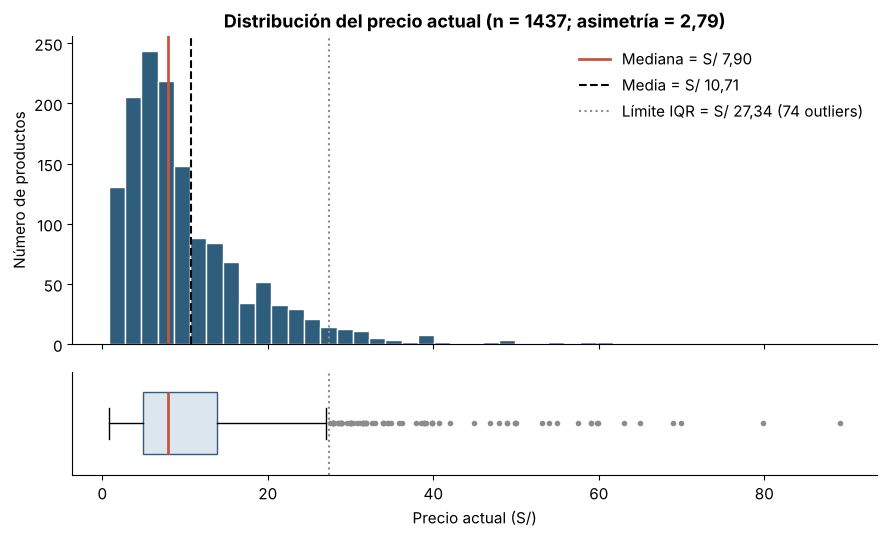

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.hist(p, bins=45, color=AZUL, edgecolor="white")
a1.axvline(A["mediana"], color=ROJO, lw=2, label=f"Mediana = S/ {nf(A['mediana'], 2)}")
a1.axvline(A["media"], color="black", lw=1.5, ls="--", label=f"Media = S/ {nf(A['media'], 2)}")
a1.axvline(A["lim_sup_iqr_preprocesamiento"], color=GRIS, lw=1.5, ls=":",
           label=f"Límite IQR = S/ {nf(A['lim_sup_iqr_preprocesamiento'], 2)} ({A['n_outliers_iqr']} outliers)")
a1.set_ylabel("Número de productos")
a1.set_title(f"Distribución del precio actual (n = {len(df)}; asimetría = {nf(A['skew'], 2)})")
a1.legend(frameon=False)
a2.boxplot(p, orientation="horizontal", widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#DCE6EE", color=AZUL), medianprops=dict(color=ROJO, lw=2),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS))
a2.axvline(A["lim_sup_iqr_preprocesamiento"], color=GRIS, lw=1.5, ls=":")
a2.set_yticks([])
a2.set_xlabel("Precio actual (S/)")
ejes_coma(a1); ejes_coma(a2, "x")
plt.tight_layout()
guardar_fig(fig, "fig02_distribucion_precio_actual.png", "Distribución del precio actual", "A",
            "A. ¿Cómo se distribuyen los precios actuales?",
            f"Mediana S/ {nf(A['mediana'], 2)} < media S/ {nf(A['media'], 2)}; asimetría {nf(A['skew'], 2)}; "
            f"{nf(A['pct_hasta_10_soles'])} % de productos cuesta hasta S/ 10; {A['n_outliers_iqr']} sobre el límite IQR "
            f"S/ {nf(A['lim_sup_iqr_preprocesamiento'], 2)}", n=len(df))
plt.show()

**Interpretación.**
- **Qué se observa:** una distribución fuertemente asimétrica a la derecha: muchos productos de bajo precio y una cola larga de productos caros.
- **Cuánto:** la mediana (S/ 7,90) es menor que la media (S/ 10,71), la asimetría es 2,79 y el 50 % central de los precios está entre S/ 4,90 y S/ 13,90 (IQR = S/ 9,00 en los 1437 productos del dataset analítico). El 64,2 % de los productos cuesta hasta S/ 10 (88,2 % hasta S/ 20). **74 productos (5,15 %) superan el límite IQR de S/ 27,34, definido en el preprocesamiento sobre los 1438 registros** (IQR = S/ 8,98); esa es la base del flag `is_price_outlier`. La diferencia entre ambos IQR se debe solo al registro fuera de alcance y no cambia el conteo.
- **Por qué importa:** con esta asimetría la media está inflada por pocos productos caros; por eso en el resto del análisis se usa la **mediana** como medida de tendencia central.
- **Relación con el objetivo:** caracteriza la estructura de precios de la oferta extraída y fija el criterio (mediana, IQR) para comparar segmentos.

**Pregunta A.2:** ¿Varía el nivel de precios entre grupos de categoría?

In [4]:
tabla_precio_grupo = (df.groupby("category_group")["current_price"]
                        .agg(n="size", media="mean", mediana="median", desv_estandar="std",
                             q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75), maximo="max")
                        .round(2).sort_values("mediana", ascending=False))
tabla_precio_grupo["iqr"] = (tabla_precio_grupo["q3"] - tabla_precio_grupo["q1"]).round(2)
tabla_precio_grupo.to_csv(TAB_DIR / "precio_por_category_group.csv", encoding="utf-8")
M["precio_por_category_group"] = {g: {"n": int(r.n), "mediana": r2(r.mediana), "media": r2(r.media),
                                      "desv_estandar": r2(r.desv_estandar), "q1": r2(r.q1), "q3": r2(r.q3),
                                      "iqr": r2(r.iqr), "maximo": r2(r.maximo)}
                                  for g, r in tabla_precio_grupo.iterrows()}
print(f"Rango de medianas entre grupos: S/ {nf(tabla_precio_grupo['mediana'].min(), 2)} "
      f"({tabla_precio_grupo['mediana'].idxmin()}) a S/ {nf(tabla_precio_grupo['mediana'].max(), 2)} "
      f"({tabla_precio_grupo['mediana'].idxmax()})")
print("Mayor IQR:", ", ".join(f"{g} S/ {nf(v, 2)}" for g, v in tabla_precio_grupo["iqr"].nlargest(3).items()))
print("Mayor máximo:", ", ".join(f"{g} S/ {nf(v, 2)}" for g, v in tabla_precio_grupo["maximo"].nlargest(2).items()))
tabla_precio_grupo

Rango de medianas entre grupos: S/ 3,95 (Fideos, Pastas y Salsas) a S/ 25,45 (Aceite)
Mayor IQR: Aceite S/ 22,75, Arroz S/ 16,77, Azúcar y Endulzantes S/ 14,60
Mayor máximo: Azúcar y Endulzantes S/ 89,20, Aceite S/ 79,90


,n,media,mediana,desv_estandar,q1,q3,maximo,iqr
category_group,,,,,,,,
Aceite,58,28.56,25.45,16.87,15.90,38.65,79.9,22.75
Azúcar y Endulzantes,42,22.30,19.75,16.78,11.22,25.82,89.2,14.60
Arroz,34,15.55,16.95,11.80,4.58,21.35,47.9,16.77
Chocolatería,115,16.18,14.90,11.19,7.90,22.10,65.0,14.20
Packs Abarrotes,60,11.04,9.70,3.99,8.50,13.05,27.5,4.55
Conservas,120,10.60,8.90,7.62,5.90,12.90,69.0,7.00
"Salsas, Cremas y Condimentos",305,9.84,8.00,6.96,4.50,13.40,36.2,8.90
Snacks y Piqueos,228,9.07,7.90,6.36,5.90,9.90,54.9,4.00
Menestras,43,5.86,5.60,1.85,4.70,6.90,10.2,2.20


Figura 4 guardada: reports/figures/fig03_precio_por_category_group.png


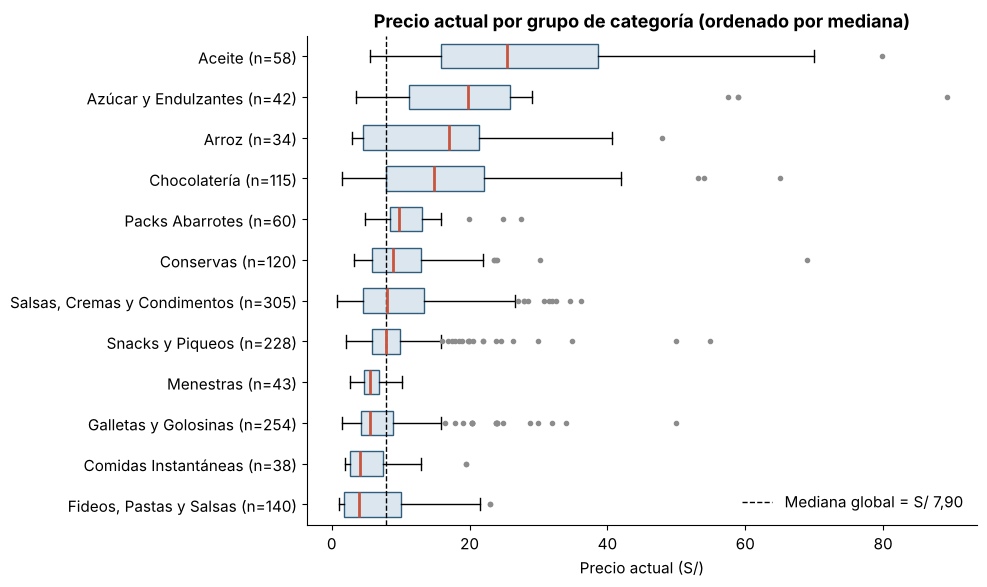

In [5]:
orden = tabla_precio_grupo.index.tolist()
etiquetas = [f"{g} (n={tabla_precio_grupo.loc[g, 'n']})" for g in orden]
fig, ax = plt.subplots(figsize=(10, 6))
datos = [df.loc[df["category_group"] == g, "current_price"] for g in orden]
ax.boxplot(datos, orientation="horizontal", tick_labels=etiquetas, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#DCE6EE", color=AZUL), medianprops=dict(color=ROJO, lw=2),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS))
ax.invert_yaxis()
ax.axvline(A["mediana"], color="black", ls="--", lw=1, label=f"Mediana global = S/ {nf(A['mediana'], 2)}")
ax.set_xlabel("Precio actual (S/)")
ax.set_title("Precio actual por grupo de categoría (ordenado por mediana)")
ax.legend(frameon=False, loc="lower right")
ejes_coma(ax, "x")
plt.tight_layout()
g_max, g_min = tabla_precio_grupo["mediana"].idxmax(), tabla_precio_grupo["mediana"].idxmin()
guardar_fig(fig, "fig03_precio_por_category_group.png", "Precio actual por grupo de categoría", "A",
            "A. ¿Varía el nivel de precios entre grupos de categoría?",
            f"Mediana desde S/ {nf(tabla_precio_grupo['mediana'].min(), 2)} ({g_min}) hasta "
            f"S/ {nf(tabla_precio_grupo['mediana'].max(), 2)} ({g_max})", n=len(df))
plt.show()

**Interpretación.**
- **Qué se observa:** los grupos difieren claramente en nivel y dispersión de precios.
- **Cuánto:** la mediana va desde S/ 3,95 en *Fideos, Pastas y Salsas* hasta S/ 25,45 en *Aceite*; *Azúcar y Endulzantes* (S/ 19,75) y *Arroz* (S/ 16,95) también superan ampliamente la mediana global (S/ 7,90). Medida con el IQR, *Aceite* (S/ 22,75) y *Arroz* (S/ 16,77) tienen la mayor dispersión; *Azúcar y Endulzantes* destaca por su máximo (S/ 89,20). La tabla exportada incluye también la desviación estándar.
- **Por qué importa:** las diferencias son coherentes con distintos tipos y tamaños de producto; los datos no permiten separar ese efecto de otros factores. Por eso comparar precios absolutos entre grupos no basta, y la sección A.3 normaliza el precio por contenido.
- **Relación con el objetivo:** responde a la comparación de precios entre grupos y explica por qué conviene analizar el **descuento en %** (relativo) y el **precio por kg o litro** además de los precios absolutos.

**Pregunta A.3:** una vez normalizado el precio por contenido (`unit_price`, S/ por kg o por litro), ¿cuánto varía el precio publicado **dentro** de una misma subcategoría?

Se usan solo los productos con contenido confirmado por el nombre (`content_validated = 1`) y, en cada subcategoría, solo la unidad predominante (no se comparan kg con litros ni con unidades). Se exige n ≥ 15 y se excluyen las subcategorías medidas en unidades y *Packs Abarrotes* (mezcla productos distintos). La dispersión se resume con el cociente Q3/Q1: un valor de 2 indica que el cuarto más caro paga, por kg o litro, al menos el doble que el cuarto más barato.

In [6]:
BASE_UP = {"g": "S/ por kg", "ml": "S/ por litro", "un": "S/ por unidad"}
val = df[df["content_validated"] == 1].copy()
# Unidad predominante de cada subcategoría (solo se compara dentro de la misma unidad)
u_pred = val.groupby("subcategory")["content_unit"].agg(lambda s: s.value_counts().index[0])
val["unidad_pred"] = val["subcategory"].map(u_pred)
base_up = val[val["content_unit"] == val["unidad_pred"]]
up_sub = (base_up.groupby("subcategory")
            .agg(category_group=("category_group", "first"), unidad=("content_unit", "first"), n=("sku", "size"),
                 q1=("unit_price", lambda s: s.quantile(0.25)), mediana=("unit_price", "median"),
                 q3=("unit_price", lambda s: s.quantile(0.75)), minimo=("unit_price", "min"), maximo=("unit_price", "max")))
up_sub["ratio_q3_q1"] = (up_sub["q3"] / up_sub["q1"]).round(2)
up_sub["ratio_max_min"] = (up_sub["maximo"] / up_sub["minimo"]).round(1)
up15 = (up_sub[(up_sub["n"] >= 15) & (up_sub["unidad"] != "un") & (up_sub.index != "Packs Abarrotes")]
          .sort_values("mediana").round(2))
up15.to_csv(TAB_DIR / "precio_unitario_subcategorias_n15.csv", encoding="utf-8")
print(f"Registros con contenido validado: {len(val)} de {len(df)}; en la unidad predominante de su subcategoría: {len(base_up)}")
print(f"Subcategorías con n ≥ 15 en kg o litro: {len(up15)}")
M["precio_unitario"] = {
    "n_content_validated": int(len(val)), "n_base_unidad_predominante": int(len(base_up)),
    "n_subcategorias_n15": int(len(up15)),
    "ratio_q3_q1_mediana": r2(up15["ratio_q3_q1"].median()),
    "ratio_q3_q1_min": r2(up15["ratio_q3_q1"].min()), "ratio_q3_q1_max": r2(up15["ratio_q3_q1"].max()),
    "subcategoria_mayor_ratio_q3_q1": up15["ratio_q3_q1"].idxmax(),
    "subcategoria_menor_ratio_q3_q1": up15["ratio_q3_q1"].idxmin(),
    "detalle": {s: {"category_group": r.category_group, "unidad": BASE_UP[r.unidad], "n": int(r.n),
                    "q1": r2(r.q1), "mediana": r2(r.mediana), "q3": r2(r.q3), "minimo": r2(r.minimo), "maximo": r2(r.maximo),
                    "ratio_q3_q1": r2(r.ratio_q3_q1), "ratio_max_min": r2(r.ratio_max_min)} for s, r in up15.iterrows()}}
up15

Registros con contenido validado: 1326 de 1437; en la unidad predominante de su subcategoría: 1174
Subcategorías con n ≥ 15 en kg o litro: 32


,category_group,unidad,n,q1,mediana,q3,minimo,maximo,ratio_q3_q1,ratio_max_min
subcategory,,,,,,,,,,
Arroz Extra,Arroz,g,22,4.00,4.32,4.80,3.19,6.00,1.20,1.9
Fideos Largos,"Fideos, Pastas y Salsas",g,38,5.04,6.00,6.44,3.90,91.60,1.28,23.5
Fideos Cortos,"Fideos, Pastas y Salsas",g,45,6.00,6.80,8.00,5.20,64.00,1.33,12.3
Salsas de Tomate,"Fideos, Pastas y Salsas",g,23,11.76,14.86,18.62,7.40,33.75,1.58,4.6
Vinagre,"Salsas, Cremas y Condimentos",ml,23,4.95,16.60,28.90,2.89,51.60,5.84,17.9
Sal y Pimienta,"Salsas, Cremas y Condimentos",g,37,13.80,20.80,129.00,1.90,270.00,9.35,142.1
Sillao,"Salsas, Cremas y Condimentos",ml,24,13.06,25.80,43.85,7.00,210.00,3.36,30.0
Ketchup,"Salsas, Cremas y Condimentos",g,15,21.32,26.35,41.23,14.00,75.45,1.93,5.4
Verduras en Conserva,Conservas,g,15,24.65,28.91,35.70,16.24,59.00,1.45,3.6


Figura 5 guardada: reports/figures/fig04_precio_unitario_subcategoria.png


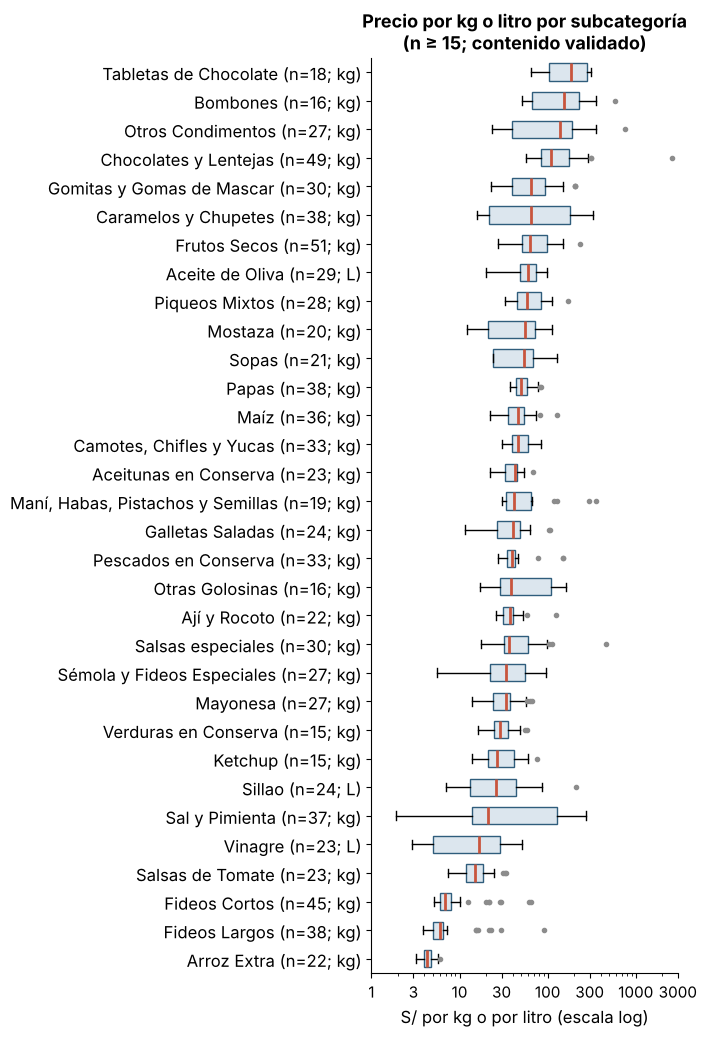

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 10.5))
orden_up = up15.index.tolist()
datos_up = [base_up.loc[base_up["subcategory"] == s, "unit_price"] for s in orden_up]
etq_up = [f"{s} (n={int(up15.loc[s, 'n'])}; {'kg' if up15.loc[s, 'unidad'] == 'g' else 'L'})" for s in orden_up]
ax.boxplot(datos_up, orientation="horizontal", tick_labels=etq_up, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#DCE6EE", color=AZUL), medianprops=dict(color=ROJO, lw=2),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS))
ejes_log_legibles(ax, "x", ticks=[1, 3, 10, 30, 100, 300, 1000, 3000], lim=(1, 3000))
ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=11)
ax.set_xlabel("S/ por kg o por litro (escala log)", fontsize=12)
ax.set_title("Precio por kg o litro por subcategoría\n(n ≥ 15; contenido validado)", fontsize=13)
plt.tight_layout()
pu = M["precio_unitario"]
guardar_fig(fig, "fig04_precio_unitario_subcategoria.png", "Precio por kg o por litro dentro de subcategorías (n ≥ 15)", "A",
            "A. ¿Cuánto varía el precio publicado dentro de una misma subcategoría una vez normalizado por contenido?",
            f"{pu['n_subcategorias_n15']} subcategorías; el cociente Q3/Q1 del precio por kg o litro va de "
            f"{nf(pu['ratio_q3_q1_min'], 2)} ({pu['subcategoria_menor_ratio_q3_q1']}) a {nf(pu['ratio_q3_q1_max'], 2)} "
            f"({pu['subcategoria_mayor_ratio_q3_q1']}); mediana {nf(pu['ratio_q3_q1_mediana'], 2)}", n=int(up15["n"].sum()))
plt.show()

**Interpretación.**
- **Qué se observa:** incluso dentro de una subcategoría y con el precio expresado por kg o litro, la dispersión es considerable y muy distinta entre subcategorías.
- **Cuánto:** de los 1326 productos con contenido validado, 1174 están en la unidad predominante de su subcategoría; 32 subcategorías cumplen n ≥ 15 en kg o litro. La mediana del precio por kg va desde S/ 4,32 (*Arroz Extra*) hasta S/ 186,14 (*Tabletas de Chocolate*). El cociente Q3/Q1 va de 1,20 en *Arroz Extra* a 9,35 en *Sal y Pimienta*, con una mediana de 1,90: subcategorías homogéneas como *Arroz Extra*, *Pescados en Conserva* (1,22) o *Fideos Largos* (1,28) contrastan con otras que mezclan productos distintos, como *Sal y Pimienta* (sal y pimienta en la misma subcategoría), *Caramelos y Chupetes* (8,23) o *Vinagre* (5,84).
- **Por qué importa:** la normalización por contenido es necesaria para comparar precios publicados entre marcas (sección D), pero solo es informativa en subcategorías homogéneas; en las heterogéneas la diferencia refleja sobre todo el tipo de producto.
- **Relación con el objetivo:** profundiza la comparación de precios publicados entre subcategorías y da un uso analítico a la variable `presentation`. Es una diferencia de precio publicado, no una medida de competitividad.

## B. Frecuencia promocional

**Pregunta B:** ¿Qué proporción de productos muestra rebaja (`has_discount = 1`) y cómo cambia esa tasa (`promo_rate`) por grupo de categoría y por marca?

**Criterio de tamaño mínimo:** una tasa calculada sobre pocos productos es inestable (con n = 5, un solo producto mueve la tasa 20 p.p.). Se exige **n ≥ 15 para grupos/subcategorías** (un producto mueve la tasa ≤ 6,7 p.p.) y **n ≥ 10 para marcas** (≤ 10 p.p.), y siempre se reporta n.

In [8]:
B = {"n_promocionados": int(df["has_discount"].sum()), "n_total": int(len(df)),
     "promo_rate_global_pct": r2(df["has_discount"].mean() * 100)}
B["ic95_global"] = [round(v, 1) for v in wilson(B["n_promocionados"], B["n_total"])]
sin_packs = df["category_group"] != "Packs Abarrotes"
B["n_sin_packs"] = int(sin_packs.sum()); B["n_promo_sin_packs"] = int(df.loc[sin_packs, "has_discount"].sum())
B["promo_rate_sin_packs_pct"] = r2(df.loc[sin_packs, "has_discount"].mean() * 100)
M["frecuencia_promocional"] = B
print(f"Productos con rebaja: {B['n_promocionados']} de {B['n_total']} → promo_rate global = {nf(B['promo_rate_global_pct'])} % "
      f"(IC 95 %: {nf(B['ic95_global'][0])}–{nf(B['ic95_global'][1])} %)")
print(f"Sin la categoría Packs Abarrotes: {B['n_promo_sin_packs']} de {B['n_sin_packs']} → {nf(B['promo_rate_sin_packs_pct'])} %")

UMBRAL_GRUPO, UMBRAL_MARCA, UMBRAL_PROMO = 15, 10, 5
promo_grupo = (df.groupby("category_group")
                 .agg(n=("sku", "size"), n_promo=("has_discount", "sum"), promo_rate=("has_discount", "mean")))
promo_grupo["promo_rate"] = (promo_grupo["promo_rate"] * 100).round(1)
promo_grupo = agregar_wilson(promo_grupo)
promo_grupo = promo_grupo[promo_grupo["n"] >= UMBRAL_GRUPO].sort_values("promo_rate", ascending=False)
promo_grupo["vs_global"] = np.where(promo_grupo["promo_rate"] >= B["promo_rate_global_pct"], "sobre la tasa global", "bajo la tasa global")
print(f"Grupos que cumplen n ≥ {UMBRAL_GRUPO}: {len(promo_grupo)} de {df['category_group'].nunique()} "
      f"(n mínimo = {promo_grupo['n'].min()})")
promo_grupo.to_csv(TAB_DIR / "promo_rate_por_category_group.csv", encoding="utf-8")
M["promo_rate_por_category_group"] = {g: {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": r2(r.promo_rate),
                                          "ic95_inf": r2(r.ic95_inf), "ic95_sup": r2(r.ic95_sup), "vs_global": r.vs_global}
                                      for g, r in promo_grupo.iterrows()}
promo_grupo

Productos con rebaja: 479 de 1437 → promo_rate global = 33,3 % (IC 95 %: 30,9–35,8 %)
Sin la categoría Packs Abarrotes: 419 de 1377 → 30,4 %
Grupos que cumplen n ≥ 15: 12 de 12 (n mínimo = 34)


,n,n_promo,promo_rate,ic95_inf,ic95_sup,vs_global
category_group,,,,,,
Packs Abarrotes,60,60,100.0,94.0,100.0,sobre la tasa global
Arroz,34,21,61.8,45.0,76.1,sobre la tasa global
"Fideos, Pastas y Salsas",140,74,52.9,44.6,60.9,sobre la tasa global
Galletas y Golosinas,254,86,33.9,28.3,39.9,sobre la tasa global
Chocolatería,115,34,29.6,22.0,38.5,bajo la tasa global
Aceite,58,17,29.3,19.2,42.0,bajo la tasa global
Menestras,43,12,27.9,16.7,42.7,bajo la tasa global
Conservas,120,31,25.8,18.8,34.3,bajo la tasa global
Snacks y Piqueos,228,57,25.0,19.8,31.0,bajo la tasa global


Figura 6 guardada: reports/figures/fig05_promo_rate_category_group.png


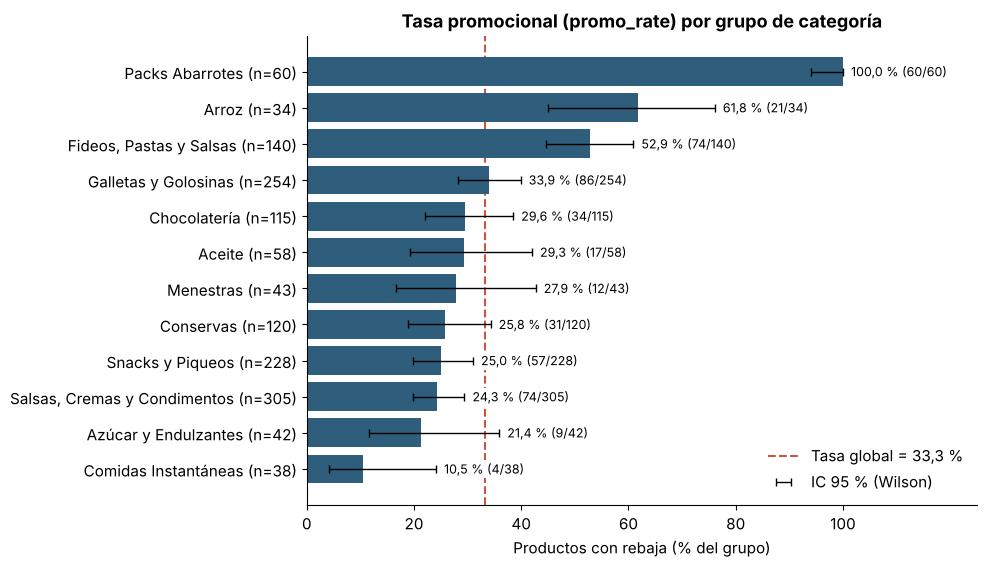

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.8))
pg = promo_grupo.sort_values("promo_rate")
y = np.arange(len(pg))
ax.axvline(B["promo_rate_global_pct"], color=ROJO, ls="--", lw=1.5, zorder=1,
           label=f"Tasa global = {nf(B['promo_rate_global_pct'])} %")
ax.barh(y, pg["promo_rate"], color=AZUL, zorder=2)
ax.errorbar(pg["promo_rate"], y, xerr=[pg["promo_rate"] - pg["ic95_inf"], pg["ic95_sup"] - pg["promo_rate"]],
            fmt="none", ecolor="black", elinewidth=1, capsize=3, zorder=3, label="IC 95 % (Wilson)")
for i, (g, r) in enumerate(pg.iterrows()):
    ax.text(r.ic95_sup + 1.5, i, f"{nf(r.promo_rate)} % ({int(r.n_promo)}/{int(r.n)})", va="center", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=5)
ax.set_yticks(y, [f"{g} (n={int(r.n)})" for g, r in pg.iterrows()])
ax.set_xlim(0, 125)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_xlabel("Productos con rebaja (% del grupo)")
ax.set_title("Tasa promocional (promo_rate) por grupo de categoría")
ax.legend(frameon=False, loc="lower right")
ejes_coma(ax, "x")
plt.tight_layout()
guardar_fig(fig, "fig05_promo_rate_category_group.png", "Tasa promocional por grupo de categoría (IC 95 %)", "B",
            "B. ¿Cómo cambia la frecuencia de rebajas por grupo de categoría?",
            f"De {nf(pg['promo_rate'].min())} % ({pg['promo_rate'].idxmin()}) a {nf(pg['promo_rate'].max())} % "
            f"({pg['promo_rate'].idxmax()}); global {nf(B['promo_rate_global_pct'])} %", n=int(pg["n"].sum()))
plt.show()

**Interpretación.**
- **Qué se observa:** la frecuencia de rebajas es muy desigual entre grupos.
- **Cuánto:** 1 de cada 3 productos muestra rebaja (tasa global 33,3 %; 479 de 1437; IC 95 %: 30,9–35,8 %). La frecuencia promocional observable se concentra en tres grupos: *Packs Abarrotes* (100 %; 60 de 60), *Arroz* (61,8 %; n = 34) y *Fideos, Pastas y Salsas* (52,9 %; n = 140), cuyos intervalos quedan por encima de la tasa global. Otros grupos de abarrotes están por debajo: *Aceite* (29,3 %; n = 58), *Menestras* (27,9 %; n = 43), *Azúcar y Endulzantes* (21,4 %; n = 42) y, en el extremo, *Comidas Instantáneas* (10,5 %; n = 38). En *Chocolatería*, *Aceite*, *Menestras*, *Conservas* y *Azúcar y Endulzantes* el IC 95 % incluye la tasa global, por lo que su diferencia con ella no es concluyente.
- **Por qué importa:** un promedio global oculta diferencias de más de 50 p.p. entre grupos. Además, *Packs Abarrotes* eleva la tasa global: sin esa categoría la tasa es 30,4 % (n = 1377).
- **Relación con el objetivo:** identifica qué segmentos de Abarrotes presentan mayor frecuencia promocional (objetivo específico 4).

In [10]:
marcas = (df.groupby("brand")
            .agg(n=("sku", "size"), n_promo=("has_discount", "sum"), promo_rate=("has_discount", "mean"),
                 precio_mediano=("current_price", "median")))
marcas["promo_rate"] = (marcas["promo_rate"] * 100).round(1)
marcas["descuento_mediano_promocionados"] = promo.groupby("brand")["discount_pct"].median().round(2)
# Tasa esperada si la marca tuviera la tasa promedio de cada grupo en el que publica (control por mezcla de grupos)
tasa_grupo = df.groupby("category_group")["has_discount"].mean()
marcas["promo_rate_esperada"] = (df["category_group"].map(tasa_grupo).groupby(df["brand"]).mean() * 100).round(1)
marcas["dif_obs_menos_esp_pp"] = (marcas["promo_rate"] - marcas["promo_rate_esperada"]).round(1)
marcas["grupo_principal"] = df.groupby("brand")["category_group"].agg(lambda s: s.value_counts().index[0])
marcas["pct_en_grupo_principal"] = (df.groupby("brand")["category_group"]
                                      .agg(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1)
marcas = agregar_wilson(marcas)
marcas_10 = marcas[marcas["n"] >= UMBRAL_MARCA].sort_values(["promo_rate", "n"], ascending=False)
marcas_10.to_csv(TAB_DIR / "marcas_n10_promociones.csv", encoding="utf-8")
marcas_10["ancho_ic_pp"] = marcas_10["ic95_sup"] - marcas_10["ic95_inf"]
print(f"Marcas con n ≥ {UMBRAL_MARCA}: {len(marcas_10)} de {len(marcas)}; "
      f"cubren {marcas_10['n'].sum()} productos ({nf(marcas_10['n'].sum()/len(df)*100)} % de la muestra)")
print(f"Ancho del IC 95 % en marcas con n entre 10 y 14: {nf(marcas_10.loc[marcas_10['n'] < 15, 'ancho_ic_pp'].min())}–"
      f"{nf(marcas_10.loc[marcas_10['n'] < 15, 'ancho_ic_pp'].max())} p.p.")
M["marcas_n10"] = {"n_marcas": int(len(marcas_10)), "n_productos": int(marcas_10["n"].sum()),
                   "pct_productos": r2(marcas_10["n"].sum() / len(df) * 100),
                   "ancho_ic95_pp_n10_14": [r2(marcas_10.loc[marcas_10["n"] < 15, "ancho_ic_pp"].min()),
                                            r2(marcas_10.loc[marcas_10["n"] < 15, "ancho_ic_pp"].max())],
                   "nota_esperada": "promo_rate_esperada = promedio de la tasa de cada grupo de categoría ponderado por los productos de la marca en ese grupo",
                   "detalle": {b: {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": r2(r.promo_rate),
                                   "ic95_inf": r2(r.ic95_inf), "ic95_sup": r2(r.ic95_sup),
                                   "promo_rate_esperada_pct": r2(r.promo_rate_esperada),
                                   "dif_obs_menos_esp_pp": r2(r.dif_obs_menos_esp_pp),
                                   "grupo_principal": r.grupo_principal, "pct_en_grupo_principal": r2(r.pct_en_grupo_principal),
                                   "descuento_mediano_pct": (None if pd.isna(r.descuento_mediano_promocionados)
                                                             else r2(r.descuento_mediano_promocionados))}
                               for b, r in marcas_10.iterrows()}}
marcas_10.drop(columns="ancho_ic_pp")

Marcas con n ≥ 10: 32 de 271; cubren 697 productos (48,5 % de la muestra)
Ancho del IC 95 % en marcas con n entre 10 y 14: 22,8–51,9 p.p.


,n,n_promo,promo_rate,precio_mediano,descuento_mediano_promocionados,promo_rate_esperada,dif_obs_menos_esp_pp,grupo_principal,pct_en_grupo_principal,ic95_inf,ic95_sup
brand,,,,,,,,,,,
PRIMOR,11,11,100.0,12.20,20.59,60.5,39.5,Packs Abarrotes,45.5,74.1,100.0
NICOLINI,14,13,92.9,1.50,11.76,50.8,42.1,"Fideos, Pastas y Salsas",92.9,68.5,98.7
DON VITTORIO,24,22,91.7,3.05,15.25,54.8,36.9,"Fideos, Pastas y Salsas",95.8,74.2,97.7
MOLITALIA,23,21,91.3,2.50,17.14,52.9,38.4,"Fideos, Pastas y Salsas",100.0,73.2,97.6
ALACENA,30,27,90.0,8.20,10.67,36.9,53.1,"Salsas, Cremas y Condimentos",83.3,74.4,96.5
OREO,14,12,85.7,6.90,8.65,62.2,23.5,Galletas y Golosinas,57.1,60.1,96.0
CASINO,13,11,84.6,4.90,10.91,49.1,35.5,Galletas y Golosinas,76.9,57.8,95.7
LAY'S,17,14,82.4,6.90,19.63,51.5,30.9,Snacks y Piqueos,64.7,59.0,93.8
VICTORIA,13,10,76.9,6.20,15.69,64.4,12.5,Galletas y Golosinas,53.8,49.7,91.8


Figura 7 guardada: reports/figures/fig06_promo_rate_marcas.png


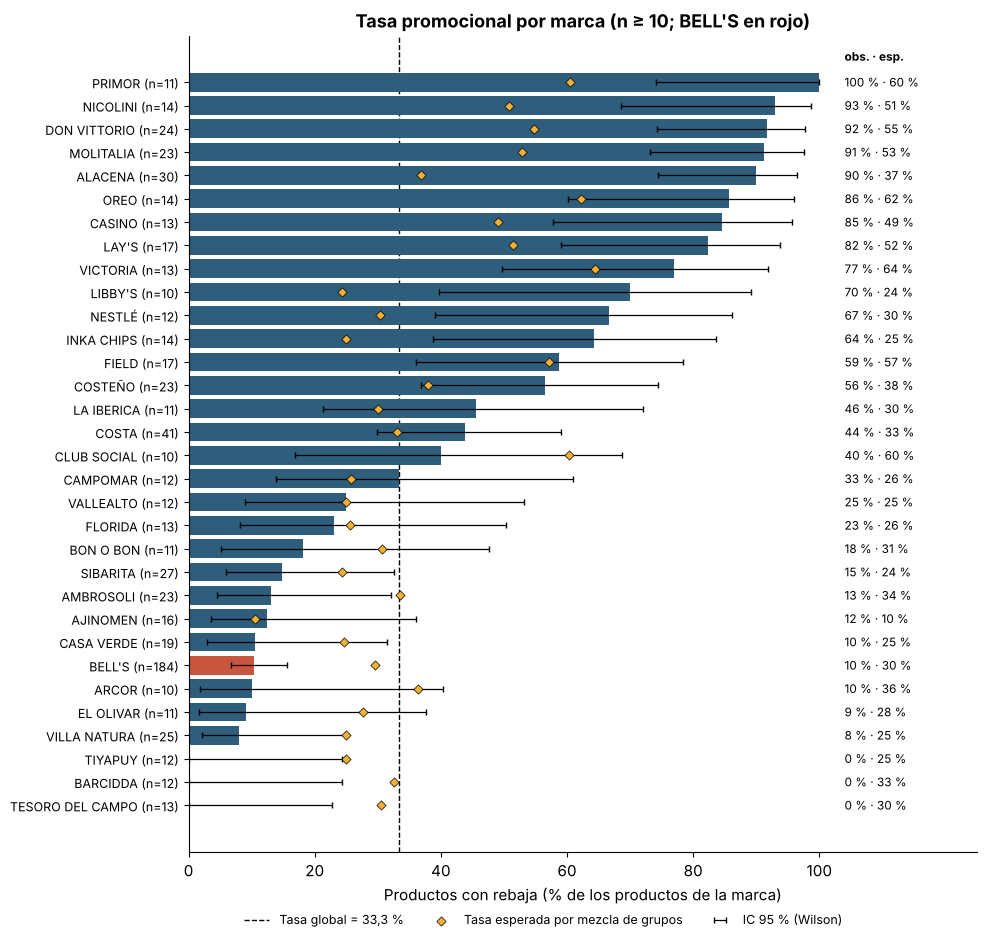

In [11]:
fig, ax = plt.subplots(figsize=(10, 9.5))
mb = marcas_10.sort_values("promo_rate")
y = np.arange(len(mb))
ax.axvline(B["promo_rate_global_pct"], color="black", ls="--", lw=1, zorder=1,
           label=f"Tasa global = {nf(B['promo_rate_global_pct'])} %")
ax.barh(y, mb["promo_rate"], color=[ROJO if b == "BELL'S" else AZUL for b in mb.index], zorder=2)
ax.errorbar(mb["promo_rate"], y, xerr=[mb["promo_rate"] - mb["ic95_inf"], mb["ic95_sup"] - mb["promo_rate"]],
            fmt="none", ecolor="black", elinewidth=0.9, capsize=2.5, zorder=3, label="IC 95 % (Wilson)")
ax.scatter(mb["promo_rate_esperada"], y, marker="D", s=22, color="#F2B134", edgecolor="black", lw=0.5, zorder=4,
           label="Tasa esperada por mezcla de grupos")
# Valores en una columna fija a la derecha (observada · esperada) para no superponerse a barras ni marcadores
ax.text(104, len(mb) - 0.2, "obs. · esp.", fontsize=8.5, fontweight="bold", va="bottom")
for i, (b, r) in enumerate(mb.iterrows()):
    ax.text(104, i, f"{nf(r.promo_rate, 0)} % · {nf(r.promo_rate_esperada, 0)} %", va="center", fontsize=8.5)
ax.set_yticks(y, [f"{b} (n={int(r.n)})" for b, r in mb.iterrows()])
ax.set_xlim(0, 125)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.tick_params(axis="y", labelsize=9)
ax.set_xlabel("Productos con rebaja (% de los productos de la marca)")
ax.set_title(f"Tasa promocional por marca (n ≥ {UMBRAL_MARCA}; BELL'S en rojo)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.06), ncol=3, fontsize=9)
ejes_coma(ax, "x")
plt.tight_layout()
n_90 = int((mb["promo_rate"] >= 90).sum()); n_0 = int((mb["promo_rate"] == 0).sum())
tasa_b, n_b = marcas.loc["BELL'S", "promo_rate"], int(marcas.loc["BELL'S", "n"])
guardar_fig(fig, "fig06_promo_rate_marcas.png", "Tasa promocional por marca (n ≥ 10): observada, IC 95 % y esperada por mezcla de grupos", "B",
            "B. ¿Qué marcas muestran rebaja con mayor frecuencia?",
            f"{n_90} marcas con tasa ≥ 90 % y {n_0} marcas con 0 %; BELL'S {nf(tasa_b)} % (n = {n_b})", n=int(mb["n"].sum()))
plt.show()

**Interpretación.**
- **Qué se observa:** entre las 32 marcas con al menos 10 productos (697 productos, 48,5 % de la muestra) hay dos comportamientos opuestos: marcas con casi todo su surtido rebajado y marcas sin ninguna rebaja.
- **Cuánto:** PRIMOR (100 %; n = 11), NICOLINI (92,9 %; n = 14), DON VITTORIO (91,7 %; n = 24), MOLITALIA (91,3 %; n = 23) y ALACENA (90,0 %; n = 30) tienen tasa ≥ 90 %, mientras que TESORO DEL CAMPO, BARCIDDA y TIYAPUY no muestran ninguna rebaja. BELL'S, la marca con más productos (n = 184), tiene una tasa de 10,3 %, muy por debajo de la global.
- **Control por mezcla de grupos:** la frecuencia promocional observable varía fuertemente entre marcas, pero marca y categoría están entrelazadas: NICOLINI, DON VITTORIO y MOLITALIA publican entre el 92,9 % y el 100 % de sus productos en *Fideos, Pastas y Salsas*, y casi la mitad de los productos de PRIMOR (45,5 %) son *Packs Abarrotes*. Por eso se calcula la **tasa esperada** de cada marca si tuviera la tasa promedio de los grupos en que publica (rombos de la figura). Las cinco marcas con tasa ≥ 90 % superan su tasa esperada en 36,9 a 53,1 p.p., y BELL'S queda 19,3 p.p. por debajo de la suya (29,6 %). Aun así, los datos no permiten atribuir la diferencia a la marca: solo describen que no se explica por la mezcla de grupos.
- **Incertidumbre:** con n entre 10 y 14, el IC 95 % tiene un ancho de 22,8 a 51,9 p.p. (p. ej., LIBBY'S 70,0 %, IC 39,7–89,2 %); las posiciones intermedias del ranking no son distinguibles entre sí.
- **Relación con el objetivo:** identifica las marcas con mayor frecuencia de productos en promoción (objetivo específico 3) con n, intervalo y tasa esperada.

**Pregunta B.3 (sensibilidad):** el notebook 02 mostró que el faltante de `presentation` no es aleatorio. ¿Cuánto cambia la tasa promocional si se excluyen los registros cuya presentación fue imputada (`presentation_imputed = 1`)?

In [12]:
def tasa(mask):
    k, n = int(df.loc[mask, "has_discount"].sum()), int(mask.sum())
    lo, hi = wilson(k, n)
    return {"n": n, "n_promo": k, "promo_rate_pct": r2(k / n * 100), "ic95_inf": round(lo, 1), "ic95_sup": round(hi, 1)}
todos = pd.Series(True, index=df.index)
imp = df["presentation_imputed"] == 1
sens = pd.DataFrame({
    "Todos los productos": tasa(todos),
    "Sin registros imputados": tasa(~imp),
    "Solo registros imputados": tasa(imp),
    "Sin Packs Abarrotes": tasa(sin_packs),
    "Sin Packs Abarrotes ni imputados": tasa(sin_packs & ~imp),
}).T
sens["dif_vs_todos_pp"] = (sens["promo_rate_pct"] - sens.loc["Todos los productos", "promo_rate_pct"]).round(2)
sens.to_csv(TAB_DIR / "sensibilidad_presentation_imputed.csv", encoding="utf-8")
M["sensibilidad_presentation_imputed"] = {k: {kk: (int(vv) if kk in ("n", "n_promo") else float(vv)) for kk, vv in r.items()}
                                          for k, r in sens.iterrows()}
M["sensibilidad_presentation_imputed"]["prueba_imputados_vs_resto"] = prueba_2x2(
    int(df.loc[imp, "has_discount"].sum()), int(imp.sum()), int(df.loc[~imp, "has_discount"].sum()), int((~imp).sum()))
print("Imputados vs. no imputados:", M["sensibilidad_presentation_imputed"]["prueba_imputados_vs_resto"])
sens

Imputados vs. no imputados: {'k1': 76, 'n1': 137, 'k2': 403, 'n2': 1300, 'tasa1_pct': 55.47, 'tasa2_pct': 31.0, 'chi2': 33.41, 'p_chi2': 7.47e-09, 'p_fisher': 2.12e-08}


,n,n_promo,promo_rate_pct,ic95_inf,ic95_sup,dif_vs_todos_pp
Todos los productos,1437.0,479.0,33.33,30.9,35.8,0.00
Sin registros imputados,1300.0,403.0,31.00,28.5,33.6,-2.33
Solo registros imputados,137.0,76.0,55.47,47.1,63.5,22.14
Sin Packs Abarrotes,1377.0,419.0,30.43,28.1,32.9,-2.90
Sin Packs Abarrotes ni imputados,1277.0,380.0,29.76,27.3,32.3,-3.57


**Interpretación.**
- **Qué se observa:** los registros imputados tienen una tasa de rebaja mucho mayor que el resto.
- **Cuánto:** 55,47 % en los 137 imputados del dataset analítico frente a 31,00 % en los 1300 no imputados (Fisher p < 0,001). Excluirlos bajaría la tasa global de 33,33 % a 31,00 % (−2,33 p.p.); sin *Packs Abarrotes* ni imputados quedaría en 29,76 % (−3,57 p.p.).
- **Por qué importa:** si los nulos se hubieran eliminado, la tasa promocional estaría subestimada en algo más de 2 p.p. Esto confirma la decisión de imputar y no eliminar, y da a `presentation_imputed` un uso analítico concreto: acotar la sensibilidad de los resultados a la calidad del dato.
- **Relación con el objetivo:** respalda la robustez de la tasa promocional reportada.

## C. Magnitud de los descuentos

**Pregunta C:** entre los productos con rebaja, ¿qué tan profundo es el descuento (en % y en S/) y cómo se reparte entre niveles de intensidad?

In [13]:
d = promo["discount_pct"]
a = promo["discount_amount"]
iqr_d = PRE["iqr"]["discount_pct (promocionados)"]
C = {"n": int(len(promo)),
     "media_pct": r2(d.mean()), "mediana_pct": r2(d.median()), "q1_pct": r2(d.quantile(0.25)),
     "q3_pct": r2(d.quantile(0.75)), "iqr_pct": r2(d.quantile(0.75) - d.quantile(0.25)),
     "min_pct": r2(d.min()), "max_pct": r2(d.max()), "skew_pct": r2(d.skew()),
     "n_mayor_20_pct": int((d > 20).sum()), "pct_mayor_20": r2((d > 20).mean() * 100),
     "n_mayor_30_pct": int((d > 30).sum()), "pct_mayor_30": r2((d > 30).mean() * 100),
     "n_exacto_10": int((d == 10).sum()), "n_exacto_20": int((d == 20).sum()),
     "lim_sup_iqr_preprocesamiento": iqr_d["lim_sup"], "n_outliers_iqr": iqr_d["n_outliers"],
     "monto_media_soles": r2(a.mean()), "monto_mediana_soles": r2(a.median()),
     "monto_q1_soles": r2(a.quantile(0.25)), "monto_q3_soles": r2(a.quantile(0.75)), "monto_max_soles": r2(a.max())}
M["magnitud_descuento_promocionados"] = C
for k, v in C.items():
    print(f"{k:>30}: {v}")

                             n: 479
                     media_pct: 15.45
                   mediana_pct: 14.71
                        q1_pct: 10.38
                        q3_pct: 20.08
                       iqr_pct: 9.7
                       min_pct: 0.69
                       max_pct: 38.14
                      skew_pct: 0.57
                n_mayor_20_pct: 121
                  pct_mayor_20: 25.26
                n_mayor_30_pct: 21
                  pct_mayor_30: 4.38
                   n_exacto_10: 11
                   n_exacto_20: 11
  lim_sup_iqr_preprocesamiento: 34.63
                n_outliers_iqr: 6
             monto_media_soles: 1.89
           monto_mediana_soles: 1.1
                monto_q1_soles: 0.6
                monto_q3_soles: 2.4
               monto_max_soles: 15.8


Figura 8 guardada: reports/figures/fig07_distribucion_descuento.png


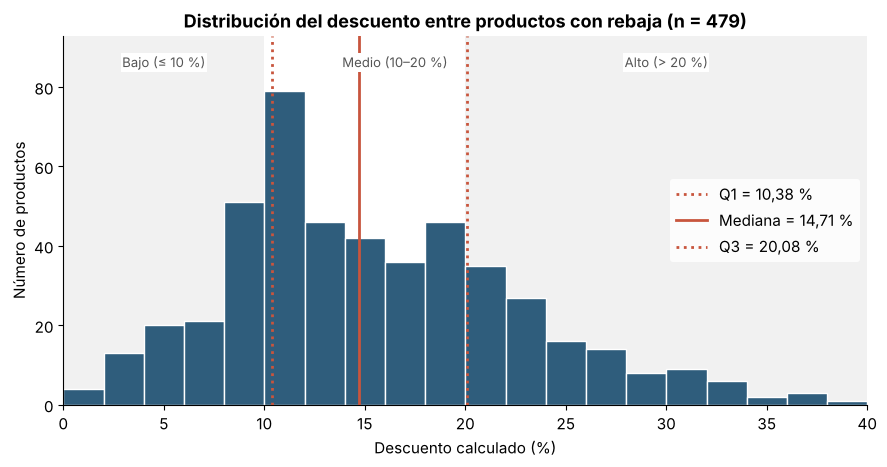

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.8))
# Bordes desplazados 0,005: un 10,00 % exacto (clase Bajo) cae en la barra 8–10 y un 20,00 % (Medio) en la 18–20
bordes = np.arange(0, 42, 2) + 0.005
ax.axvspan(0, 10.005, color=GRIS_CLARO, alpha=0.35, lw=0, zorder=0)
ax.axvspan(20.005, 40, color=GRIS_CLARO, alpha=0.35, lw=0, zorder=0)
ax.hist(d, bins=bordes, color=AZUL, edgecolor="white", zorder=2)
for x, txt, est in [(C["q1_pct"], "Q1", ":"), (C["mediana_pct"], "Mediana", "-"), (C["q3_pct"], "Q3", ":")]:
    ax.axvline(x, color=ROJO, ls=est, lw=2, zorder=4, label=f"{txt} = {nf(x, 2)} %")
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ytxt = ax.get_ylim()[1] * 0.95
for x, txt in [(5, "Bajo (≤ 10 %)"), (16.5, "Medio (10–20 %)"), (30, "Alto (> 20 %)")]:
    ax.text(x, ytxt, txt, ha="center", va="top", color="#555555", fontsize=9.5,
            bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=5)
ax.set_xlim(0, 40)
ax.set_xlabel("Descuento calculado (%)")
ax.set_ylabel("Número de productos")
ax.set_title(f"Distribución del descuento entre productos con rebaja (n = {C['n']})")
ax.legend(frameon=True, facecolor="white", edgecolor="none", loc="center right")
ejes_coma(ax)
plt.tight_layout()
guardar_fig(fig, "fig07_distribucion_descuento.png", "Distribución del descuento entre productos con rebaja", "C",
            "C. ¿Qué tan profundos son los descuentos?",
            f"Mediana {nf(C['mediana_pct'], 2)} %, IQR {nf(C['q1_pct'], 2)}–{nf(C['q3_pct'], 2)} %, máximo {nf(C['max_pct'], 2)} %; "
            f"{C['n_mayor_30_pct']} productos ({nf(C['pct_mayor_30'])} %) sobre 30 %", n=C["n"])
plt.show()

**Interpretación.**
- **Qué se observa:** los descuentos son moderados y se concentran alrededor de 15 %, sin la cola extrema que tienen los precios.
- **Cuánto:** media 15,45 % y mediana 14,71 %; el 50 % central está entre 10,38 % y 20,08 % (IQR = 9,70 p.p.); el máximo es 38,14 %. Solo 21 productos (4,4 % de los promocionados) superan 30 %. En soles, el ahorro mediano por producto es S/ 1,10 (Q1 = S/ 0,60; Q3 = S/ 2,40; máximo S/ 15,80).
- **Por qué importa:** la cercanía entre media y mediana indica que el descuento “típico” en la fecha de extracción está bien representado por ~15 %; los descuentos sobre 30 % son excepcionales y conviene revisarlos uno a uno.
- **Relación con el objetivo:** cuantifica la profundidad de las promociones y justifica empíricamente los cortes 10/20 de `promotion_intensity` (coinciden con Q1 y Q3).

*Nota de lectura de la figura:* los bordes de las barras están desplazados 0,005 p.p., de modo que los 11 descuentos de exactamente 10,00 % (clase *Bajo*) quedan en la barra 8–10 y los 11 de exactamente 20,00 % (clase *Medio*) en la barra 18–20, en coherencia con las franjas sombreadas.

In [15]:
dist_int = pd.Series({k: int((df["promotion_intensity"] == k).sum()) for k in ORDEN_INT})
dist_int_promo = dist_int.drop("Sin descuento")
tabla_int = pd.DataFrame({"n": dist_int, "pct_total": (dist_int / len(df) * 100).round(1),
                          "pct_promocionados": (dist_int_promo / dist_int_promo.sum() * 100).round(1)}).reindex(ORDEN_INT)
tabla_int.index.name = "promotion_intensity"
tabla_int.to_csv(TAB_DIR / "distribucion_promotion_intensity.csv", encoding="utf-8")
M["promotion_intensity"] = {k: {"n": int(r.n), "pct_total": r2(r.pct_total),
                                "pct_promocionados": (None if pd.isna(r.pct_promocionados) else r2(r.pct_promocionados))}
                            for k, r in tabla_int.iterrows()}
tabla_int

,n,pct_total,pct_promocionados
promotion_intensity,,,
Sin descuento,958,66.7,NaN
Bajo,109,7.6,22.8
Medio,249,17.3,52.0
Alto,121,8.4,25.3


Figura A6 guardada: reports/figures/fig08_intensidad_promocional.png


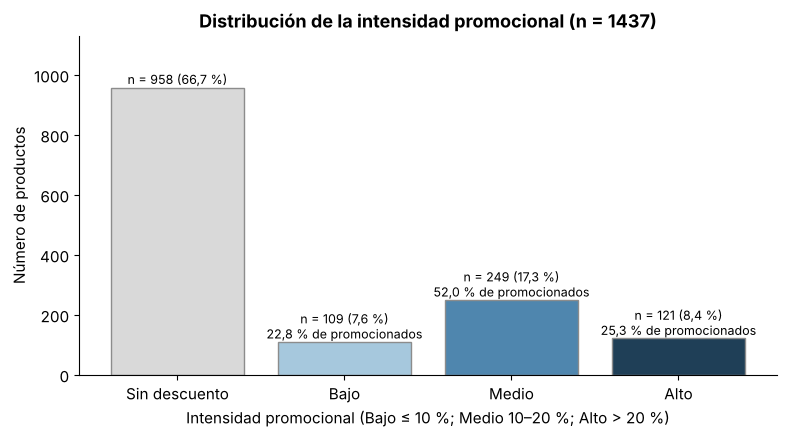

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(ORDEN_INT, dist_int.values, color=[COLORES_INT[k] for k in ORDEN_INT], edgecolor=GRIS)
for i, k in enumerate(ORDEN_INT):
    extra = "" if k == "Sin descuento" else f"\n{nf(tabla_int.loc[k, 'pct_promocionados'])} % de promocionados"
    ax.text(i, dist_int[k] + 12, f"n = {dist_int[k]} ({nf(tabla_int.loc[k, 'pct_total'])} %){extra}",
            ha="center", fontsize=9)
ax.set_ylim(0, dist_int.max() * 1.18)
ax.set_xlabel("Intensidad promocional (Bajo ≤ 10 %; Medio 10–20 %; Alto > 20 %)")
ax.set_ylabel("Número de productos")
ax.set_title(f"Distribución de la intensidad promocional (n = {len(df)})")
plt.tight_layout()
guardar_fig(fig, "fig08_intensidad_promocional.png", "Distribución de la intensidad promocional", "C",
            "C. ¿Cómo se reparten los productos entre niveles de descuento?",
            f"Medio = {nf(tabla_int.loc['Medio','pct_promocionados'])} % de los promocionados; "
            f"Alto = {nf(tabla_int.loc['Alto','pct_promocionados'])} %; Bajo = {nf(tabla_int.loc['Bajo','pct_promocionados'])} %", n=len(df))
plt.show()

**Interpretación.**
- **Qué se observa:** dos tercios de la muestra no muestran rebaja; entre los promocionados predomina el nivel *Medio*.
- **Cuánto:** 958 productos sin descuento (66,7 %). De los 479 promocionados, 52,0 % tiene descuento *Medio* (10–20 %), 25,3 % *Alto* (> 20 %) y 22,8 % *Bajo* (≤ 10 %). La sensibilidad a los cortes (notebook 02, sección 7.1) confirma que *Medio* predomina con cortes alternativos.
- **Por qué importa:** la intensidad *Medio* es el “estándar” promocional observable; los segmentos con más peso de *Alto* son los que muestran rebajas más profundas.
- **Relación con el objetivo:** traduce el descuento continuo a niveles comparables entre marcas y categorías (se usa en la sección E).

## D. Marcas

**Pregunta D:** ¿Qué marcas concentran los productos de las 30 páginas extraídas y las promociones, con qué tasa y profundidad? ¿Cuál es el peso de BELL'S, la marca con más productos en la muestra, y cómo se comporta frente al resto (en frecuencia de rebaja y en precio por kg o litro)?

In [17]:
D = {"n_marcas": int(len(marcas)),
     "n_marcas_menos_10": int((marcas["n"] < UMBRAL_MARCA).sum()),
     "pct_productos_marcas_menos_10": r2(marcas.loc[marcas["n"] < UMBRAL_MARCA, "n"].sum() / len(df) * 100),
     "n_marcas_un_solo_producto": int((marcas["n"] == 1).sum())}
print(f"Marcas: {D['n_marcas']} | con menos de 10 productos: {D['n_marcas_menos_10']} "
      f"({nf(D['pct_productos_marcas_menos_10'])} % de los productos) | con un solo producto: {D['n_marcas_un_solo_producto']}")

top_n = marcas.sort_values("n", ascending=False).head(10)[["n", "n_promo", "promo_rate", "descuento_mediano_promocionados"]]
top_promo = marcas.sort_values(["n_promo", "n"], ascending=False).head(10)[["n", "n_promo", "promo_rate", "descuento_mediano_promocionados"]]
print("\nTop 10 marcas por número de productos:")
display(top_n)
print("Top 10 marcas por número de productos con rebaja:")
display(top_promo)
top_n.to_csv(TAB_DIR / "top_marcas_por_productos.csv", encoding="utf-8")
top_promo.to_csv(TAB_DIR / "top_marcas_por_promociones.csv", encoding="utf-8")
D["top10_por_productos"] = {b: {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": r2(r.promo_rate)} for b, r in top_n.iterrows()}
D["top10_por_promociones"] = {b: {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": r2(r.promo_rate)} for b, r in top_promo.iterrows()}

# Descuento mediano por marca: solo marcas con al menos 5 productos promocionados
desc_marca = (promo.groupby("brand")["discount_pct"].agg(n_promo="size", descuento_mediano="median")
                .query("n_promo >= 5").sort_values("descuento_mediano", ascending=False).round(2))
desc_marca.to_csv(TAB_DIR / "descuento_mediano_por_marca_npromo5.csv", encoding="utf-8")
print("Descuento mediano por marca (marcas con ≥ 5 productos promocionados):")
display(desc_marca)
D["descuento_mediano_marcas_npromo5"] = {b: {"n_promo": int(r.n_promo), "descuento_mediano_pct": r2(r.descuento_mediano)}
                                        for b, r in desc_marca.iterrows()}

Marcas: 271 | con menos de 10 productos: 239 (51,5 % de los productos) | con un solo producto: 76

Top 10 marcas por número de productos:


,n,n_promo,promo_rate,descuento_mediano_promocionados
brand,,,,
BELL'S,184,19,10.3,8.60
COSTA,41,18,43.9,20.87
ALACENA,30,27,90.0,10.67
SIBARITA,27,4,14.8,11.95
VILLA NATURA,25,2,8.0,12.00
DON VITTORIO,24,22,91.7,15.25
COSTEÑO,23,13,56.5,20.00
MOLITALIA,23,21,91.3,17.14
AMBROSOLI,23,3,13.0,18.35


Top 10 marcas por número de productos con rebaja:


,n,n_promo,promo_rate,descuento_mediano_promocionados
brand,,,,
ALACENA,30,27,90.0,10.67
DON VITTORIO,24,22,91.7,15.25
MOLITALIA,23,21,91.3,17.14
BELL'S,184,19,10.3,8.60
COSTA,41,18,43.9,20.87
LAY'S,17,14,82.4,19.63
COSTEÑO,23,13,56.5,20.00
NICOLINI,14,13,92.9,11.76
OREO,14,12,85.7,8.65


Descuento mediano por marca (marcas con ≥ 5 productos promocionados):


,n_promo,descuento_mediano
brand,,
SALMAS,5,24.04
TAKIS,6,23.51
VICTORIA GLACITAS,6,22.64
COSTA,18,20.87
NESTLÉ,8,20.80
LIBBY'S,7,20.80
PRIMOR,11,20.59
COSTEÑO,13,20.00
LAY'S,14,19.63


In [18]:
# BELL'S: peso en la muestra y comportamiento promocional frente al resto
es_bells = df["brand"] == "BELL'S"
bells = {"n": int(es_bells.sum()), "pct_muestra": r2(es_bells.mean() * 100),
         "n_promo": int(df.loc[es_bells, "has_discount"].sum()),
         "promo_rate_pct": r2(df.loc[es_bells, "has_discount"].mean() * 100),
         "n_promo_resto": int(df.loc[~es_bells, "has_discount"].sum()),
         "promo_rate_resto_pct": r2(df.loc[~es_bells, "has_discount"].mean() * 100),
         "n_resto": int((~es_bells).sum()),
         "promo_rate_esperada_pct": r2(marcas.loc["BELL'S", "promo_rate_esperada"]),
         "descuento_mediano_pct": r2(promo.loc[promo["brand"] == "BELL'S", "discount_pct"].median()),
         "descuento_mediano_resto_pct": r2(promo.loc[promo["brand"] != "BELL'S", "discount_pct"].median()),
         "n_category_group": int(df.loc[es_bells, "category_group"].nunique()),
         "n_subcategorias": int(df.loc[es_bells, "subcategory"].nunique())}
bells["prueba_vs_resto"] = prueba_2x2(bells["n_promo"], bells["n"], bells["n_promo_resto"], bells["n_resto"])
# Comparación dentro de cada grupo (misma mezcla de categorías): tasa BELL'S vs resto
comp = (df.assign(es_bells=np.where(es_bells, "BELL'S", "Resto"))
          .pivot_table(index="category_group", columns="es_bells", values="has_discount",
                       aggfunc=["size", "sum", "mean"]))
comp.columns = [f"{a}_{b}" for a, b in comp.columns]
comp = comp.rename(columns={"size_BELL'S": "n_bells", "size_Resto": "n_resto", "sum_BELL'S": "n_promo_bells",
                            "sum_Resto": "n_promo_resto", "mean_BELL'S": "promo_rate_bells", "mean_Resto": "promo_rate_resto"})
comp[["promo_rate_bells", "promo_rate_resto"]] = (comp[["promo_rate_bells", "promo_rate_resto"]] * 100).round(1)
comp[["n_bells", "n_resto", "n_promo_bells", "n_promo_resto"]] = comp[["n_bells", "n_resto", "n_promo_bells", "n_promo_resto"]].fillna(0).astype(int)
comp = comp[comp["n_bells"] >= 5].sort_values("n_bells", ascending=False)
comp = comp[["n_bells", "n_promo_bells", "promo_rate_bells", "n_resto", "n_promo_resto", "promo_rate_resto"]]
comp.to_csv(TAB_DIR / "bells_vs_resto_por_category_group.csv", encoding="utf-8")
bells["grupos_con_n_bells_5"] = int(len(comp))
bells["grupos_bells_tasa_menor_que_resto"] = int((comp["promo_rate_bells"] < comp["promo_rate_resto"]).sum())
bells["por_grupo"] = {g: {k: (float(v) if "rate" in k else int(v)) for k, v in r.items()} for g, r in comp.iterrows()}
print(json.dumps({k: v for k, v in bells.items() if k != "por_grupo"}, indent=2, ensure_ascii=False))
comp

{
  "n": 184,
  "pct_muestra": 12.8,
  "n_promo": 19,
  "promo_rate_pct": 10.33,
  "n_promo_resto": 460,
  "promo_rate_resto_pct": 36.71,
  "n_resto": 1253,
  "promo_rate_esperada_pct": 29.6,
  "descuento_mediano_pct": 8.6,
  "descuento_mediano_resto_pct": 15.0,
  "n_category_group": 10,
  "n_subcategorias": 53,
  "prueba_vs_resto": {
    "k1": 19,
    "n1": 184,
    "k2": 460,
    "n2": 1253,
    "tasa1_pct": 10.33,
    "tasa2_pct": 36.71,
    "chi2": 50.26,
    "p_chi2": 1.34e-12,
    "p_fisher": 2.31e-14
  },
  "grupos_con_n_bells_5": 9,
  "grupos_bells_tasa_menor_que_resto": 7
}


,n_bells,n_promo_bells,promo_rate_bells,n_resto,n_promo_resto,promo_rate_resto
category_group,,,,,,
"Salsas, Cremas y Condimentos",45,0,0.0,260,74,28.5
Snacks y Piqueos,40,0,0.0,188,57,30.3
Conservas,23,7,30.4,97,24,24.7
Menestras,15,2,13.3,28,10,35.7
Aceite,14,1,7.1,44,16,36.4
"Fideos, Pastas y Salsas",14,0,0.0,126,74,58.7
Azúcar y Endulzantes,13,1,7.7,29,8,27.6
Galletas y Golosinas,10,2,20.0,244,84,34.4
Arroz,9,6,66.7,25,15,60.0


In [19]:
# Precio por kg o litro de BELL'S frente al resto dentro de la misma subcategoría (contenido validado, misma unidad)
filas = []
for s, g in base_up.groupby("subcategory"):
    gb, gr = g[g["brand"] == "BELL'S"], g[g["brand"] != "BELL'S"]
    if len(gb) >= 5 and len(gr) >= 5 and g["content_unit"].iloc[0] != "un":
        filas.append({"subcategory": s, "unidad": BASE_UP[g["content_unit"].iloc[0]], "n_bells": len(gb), "n_resto": len(gr),
                      "mediana_bells": round(gb["unit_price"].median(), 2), "mediana_resto": round(gr["unit_price"].median(), 2)})
bells_up = pd.DataFrame(filas).set_index("subcategory")
bells_up["ratio_bells_resto"] = (bells_up["mediana_bells"] / bells_up["mediana_resto"]).round(2)
bells_up = bells_up.sort_values("ratio_bells_resto")
bells_up.to_csv(TAB_DIR / "bells_vs_resto_precio_unitario.csv", encoding="utf-8")
bells["precio_unitario_vs_resto"] = {
    "n_subcategorias": int(len(bells_up)),
    "n_subcategorias_bells_menor": int((bells_up["ratio_bells_resto"] < 1).sum()),
    "ratio_mediano": r2(bells_up["ratio_bells_resto"].median()),
    "ratio_min": r2(bells_up["ratio_bells_resto"].min()), "ratio_max": r2(bells_up["ratio_bells_resto"].max()),
    "detalle": {s: {k: (float(v) if not isinstance(v, str) else v) for k, v in r.items()} for s, r in bells_up.iterrows()}}
D["bells"] = bells
M["marcas"] = D
print(json.dumps({k: v for k, v in bells["precio_unitario_vs_resto"].items() if k != "detalle"}, ensure_ascii=False))
bells_up

{"n_subcategorias": 10, "n_subcategorias_bells_menor": 9, "ratio_mediano": 0.81, "ratio_min": 0.66, "ratio_max": 1.18}


,unidad,n_bells,n_resto,mediana_bells,mediana_resto,ratio_bells_resto
subcategory,,,,,,
Sal y Pimienta,S/ por kg,7,30,13.80,20.90,0.66
"Camotes, Chifles y Yucas",S/ por kg,6,27,35.77,52.67,0.68
Pescados en Conserva,S/ por kg,7,26,28.50,40.36,0.71
Fideos Cortos,S/ por kg,5,40,5.20,7.20,0.72
Aceite de Oliva,S/ por litro,5,24,47.00,63.00,0.75
Frutos Secos,S/ por kg,16,35,55.50,63.60,0.87
Papas,S/ por kg,7,31,43.70,50.37,0.87
Arroz Extra,S/ por kg,5,17,3.85,4.38,0.88
Aceitunas en Conserva,S/ por kg,9,14,41.92,42.60,0.98


Figura A4 guardada: reports/figures/figA4_top_marcas_productos.png


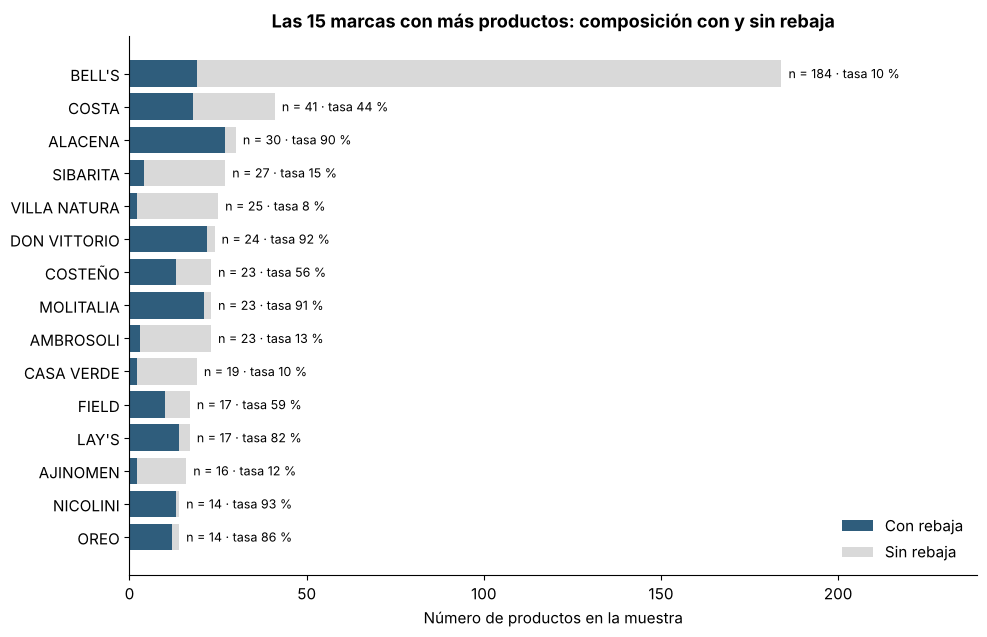

In [20]:
top15 = marcas.sort_values("n", ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(top15.index, top15["n_promo"], color=AZUL, label="Con rebaja")
ax.barh(top15.index, top15["n"] - top15["n_promo"], left=top15["n_promo"], color=GRIS_CLARO, label="Sin rebaja")
for i, (b, r) in enumerate(top15.iterrows()):
    ax.text(r.n + 2, i, f"n = {int(r.n)} · tasa {nf(r.promo_rate, 0)} %", va="center", fontsize=9)
ax.set_xlim(0, top15["n"].max() * 1.3)
ax.set_xlabel("Número de productos en la muestra")
ax.set_title("Las 15 marcas con más productos: composición con y sin rebaja")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
guardar_fig(fig, "figA4_top_marcas_productos.png", "Las 15 marcas con más productos: composición con y sin rebaja", "D",
            "D. ¿Qué marcas concentran la oferta extraída y cuántas de sus referencias tienen rebaja?",
            f"BELL'S: {bells['n']} productos ({nf(bells['pct_muestra'])} % de la muestra) y tasa {nf(bells['promo_rate_pct'])} % "
            f"vs {nf(bells['promo_rate_resto_pct'])} % del resto", n=int(top15["n"].sum()))
plt.show()

**Interpretación.**
- **Qué se observa:** la muestra extraída está fragmentada en muchas marcas, con una sola marca destacada en número de productos: BELL'S.
- **Cuánto:** en las 30 páginas extraídas hay 271 marcas; 239 tienen menos de 10 productos y concentran el 51,5 % de la muestra (76 marcas aparecen con un único producto). BELL'S es la marca con más productos (184; 12,8 %), presentes en 10 grupos de categoría y 53 subcategorías, pero solo 19 tienen rebaja (10,3 %) frente al 36,7 % del resto de marcas (n = 1253; χ² = 50,26, Fisher p < 0,001). La diferencia se mantiene dentro de los grupos: en 7 de los 9 grupos donde BELL'S tiene al menos 5 productos su tasa es menor que la del resto (p. ej., 0 % frente a 28,5 % en *Salsas, Cremas y Condimentos* y 0 % frente a 58,7 % en *Fideos, Pastas y Salsas*); las excepciones son *Conservas* (30,4 % vs 24,7 %) y *Arroz* (66,7 % vs 60,0 %). Cuando BELL'S rebaja, su descuento mediano es menor (8,60 % frente a 15,00 %) y 4 de las 12 rebajas simbólicas (< 3 %) de la sección G son suyas.
- **Precio por kg o litro:** en las 10 subcategorías donde BELL'S y el resto tienen al menos 5 productos con contenido validado, la mediana de BELL'S es menor en 9; el cociente BELL'S/resto tiene una mediana de 0,81 (de 0,66 en *Sal y Pimienta* a 1,18 en *Otros Condimentos*).
- **Por qué importa:** en esta muestra, BELL'S rara vez aparece con rebaja, pero su precio publicado por kg o litro suele ser menor que el de otras marcas de la misma subcategoría. Los datos **no permiten** explicar el motivo de ninguna de las dos diferencias: solo describen lo observado en una fecha.
- **Relación con el objetivo:** muestra diferencias en la estrategia promocional y en el precio publicado entre marcas. **Advertencia:** las marcas con menos de 10 productos no se rankean, porque una sola rebaja cambiaría su tasa en más de 10 p.p.; el detalle de las 15 marcas con más productos está en la Figura A4 (Anexo A del informe).

## E. Grupos de categoría y subcategorías

**Pregunta E:** ¿Qué grupos y subcategorías combinan mayor frecuencia y mayor profundidad de descuento (intensidad promocional observable)?

In [21]:
resumen_grupo = df.groupby("category_group").agg(
    n=("sku", "size"), precio_mediano=("current_price", "median"),
    promo_rate=("has_discount", "mean"))
resumen_grupo["promo_rate"] = (resumen_grupo["promo_rate"] * 100).round(1)
resumen_grupo["n_promo"] = df.groupby("category_group")["has_discount"].sum()
resumen_grupo["descuento_mediano_promocionados"] = promo.groupby("category_group")["discount_pct"].median().round(2)
# Con menos de 5 promocionados la mediana del descuento es solo referencial (mismo umbral aplicado a marcas)
resumen_grupo["mediana_referencial"] = resumen_grupo["n_promo"] < UMBRAL_PROMO
ct = pd.crosstab(df["category_group"], df["promotion_intensity"], normalize="index").reindex(columns=ORDEN_INT) * 100
resumen_grupo["pct_alto"] = ct["Alto"].round(1)
resumen_grupo = resumen_grupo.sort_values("promo_rate", ascending=False)
resumen_grupo.to_csv(TAB_DIR / "resumen_por_category_group.csv", encoding="utf-8")
ct.round(1).to_csv(TAB_DIR / "crosstab_intensidad_por_category_group.csv", encoding="utf-8")
M["resumen_por_category_group"] = {g: {"n": int(r.n), "precio_mediano": r2(r.precio_mediano),
                                       "promo_rate_pct": r2(r.promo_rate), "n_promo": int(r.n_promo),
                                       "descuento_mediano_pct": r2(r.descuento_mediano_promocionados),
                                       "mediana_referencial_n_promo_menor_5": bool(r.mediana_referencial),
                                       "pct_alto": r2(r.pct_alto)}
                                   for g, r in resumen_grupo.iterrows()}
resumen_grupo

,n,precio_mediano,promo_rate,n_promo,descuento_mediano_promocionados,mediana_referencial,pct_alto
category_group,,,,,,,
Packs Abarrotes,60,9.70,100.0,60,19.85,False,43.3
Arroz,34,16.95,61.8,21,10.26,False,8.8
"Fideos, Pastas y Salsas",140,3.95,52.9,74,15.74,False,7.9
Galletas y Golosinas,254,5.50,33.9,86,11.93,False,9.1
Chocolatería,115,14.90,29.6,34,20.14,False,16.5
Aceite,58,25.45,29.3,17,12.92,False,0.0
Menestras,43,5.60,27.9,12,20.00,False,9.3
Conservas,120,8.90,25.8,31,10.17,False,3.3
Snacks y Piqueos,228,7.90,25.0,57,14.49,False,5.3


Figura A7 guardada: reports/figures/fig09_descuento_por_category_group.png


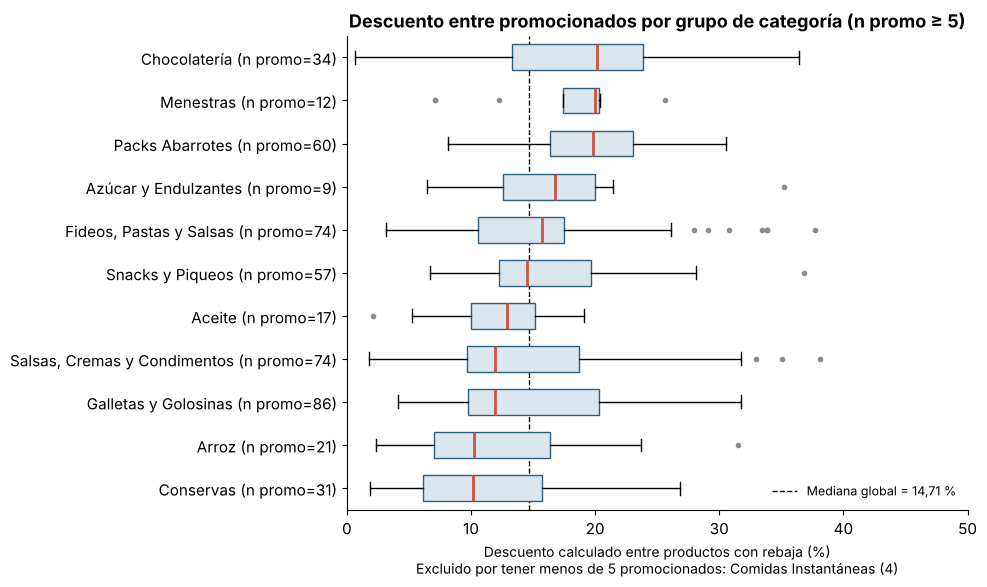

In [22]:
# Distribución del descuento entre promocionados por grupo (solo grupos con al menos 5 promocionados)
g_ok = resumen_grupo[resumen_grupo["n_promo"] >= UMBRAL_PROMO].sort_values("descuento_mediano_promocionados").index.tolist()
g_excl = resumen_grupo[resumen_grupo["n_promo"] < UMBRAL_PROMO].index.tolist()
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([promo.loc[promo["category_group"] == g, "discount_pct"] for g in g_ok], orientation="horizontal",
           tick_labels=[f"{g} (n promo={int(resumen_grupo.loc[g, 'n_promo'])})" for g in g_ok], widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#DCE6EE", color=AZUL), medianprops=dict(color=ROJO, lw=2),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS))
ax.axvline(C["mediana_pct"], color="black", ls="--", lw=1, zorder=1, label=f"Mediana global = {nf(C['mediana_pct'], 2)} %")
ax.set_xlabel("Descuento calculado entre productos con rebaja (%)")
ax.set_title("Descuento entre promocionados por grupo de categoría (n promo ≥ 5)")
ax.set_xlim(0, 50)
ax.legend(frameon=True, facecolor="white", edgecolor="none", loc="lower right", fontsize=9)
if g_excl:
    ax.set_xlabel("Descuento calculado entre productos con rebaja (%)\nExcluido por tener menos de 5 promocionados: "
                  + ", ".join(f"{g} ({int(resumen_grupo.loc[g, 'n_promo'])})" for g in g_excl), fontsize=10)
ejes_coma(ax, "x")
plt.tight_layout()
rg_ok = resumen_grupo.loc[g_ok, "descuento_mediano_promocionados"]
M["descuento_por_category_group"] = {"grupos": g_ok, "excluidos_n_promo_menor_5": g_excl,
                                     "mediana_min": {"grupo": rg_ok.idxmin(), "valor": r2(rg_ok.min())},
                                     "mediana_max": {"grupo": rg_ok.idxmax(), "valor": r2(rg_ok.max())}}
guardar_fig(fig, "fig09_descuento_por_category_group.png", "Descuento entre promocionados por grupo de categoría (n promo ≥ 5)", "E",
            "E. ¿Qué tan profundos son los descuentos en cada grupo?",
            f"Mediana desde {nf(rg_ok.min(), 2)} % ({rg_ok.idxmin()}) hasta {nf(rg_ok.max(), 2)} % ({rg_ok.idxmax()})",
            n=int(resumen_grupo.loc[g_ok, "n_promo"].sum()))
plt.show()

Figura 9 guardada: reports/figures/fig10_intensidad_por_category_group.png


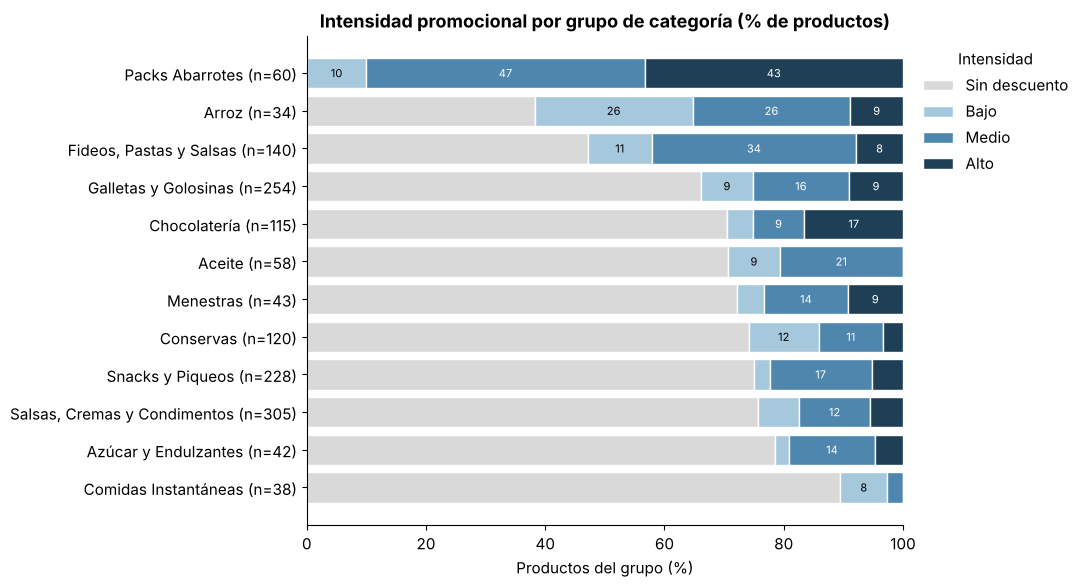

In [23]:
orden_e = resumen_grupo.sort_values("promo_rate").index
ct_plot = ct.loc[orden_e]
fig, ax = plt.subplots(figsize=(11, 6))
izq = np.zeros(len(ct_plot))
for k in ORDEN_INT:
    ax.barh([f"{g} (n={resumen_grupo.loc[g, 'n']})" for g in ct_plot.index], ct_plot[k], left=izq,
            color=COLORES_INT[k], label=k, edgecolor="white")
    for i, (v, l) in enumerate(zip(ct_plot[k], izq)):
        if v >= 7 and k != "Sin descuento":
            ax.text(l + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if k in ["Medio", "Alto"] else "black")
    izq += ct_plot[k].values
ax.set_xlim(0, 100)
ax.set_xlabel("Productos del grupo (%)")
ax.set_title("Intensidad promocional por grupo de categoría (% de productos)")
ax.legend(title="Intensidad", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
g_alto = ct["Alto"].drop("Packs Abarrotes").idxmax()
guardar_fig(fig, "fig10_intensidad_por_category_group.png", "Intensidad promocional por grupo de categoría", "E",
            "E. ¿Qué grupos combinan mayor frecuencia y profundidad de descuento?",
            f"Packs Abarrotes: {nf(ct.loc['Packs Abarrotes','Alto'])} % en nivel Alto; entre los demás grupos, "
            f"{g_alto} lidera con {nf(ct.loc[g_alto,'Alto'])} %", n=len(df))
plt.show()

**Interpretación.**
- **Qué se observa:** frecuencia y profundidad no siempre van juntas. Algunos grupos rebajan muchos productos con descuentos moderados y otros rebajan pocos pero con mayor profundidad.
- **Cuánto:** entre los grupos con al menos 5 promocionados, el descuento mediano va de 10,17 % (*Conservas*) a 20,14 % (*Chocolatería*). *Packs Abarrotes* combina ambas dimensiones: 100 % con rebaja, descuento mediano 19,85 % y 43,3 % de sus productos en nivel *Alto*. *Arroz* tiene la segunda mayor tasa (61,8 %) pero uno de los descuentos medianos más bajos (10,26 %). *Chocolatería* (29,6 % de tasa) y *Menestras* (27,9 %) rebajan menos productos pero con descuentos medianos de ~20 %. *Comidas Instantáneas* tiene la menor tasa (10,5 %); su descuento mediano (4,82 %) se calcula sobre solo 4 productos rebajados, por lo que es **referencial** y se excluye de la Figura A7 (Anexo A; mismo umbral n promo ≥ 5 aplicado a marcas).
- **Por qué importa:** la “intensidad promocional” debe leerse en dos dimensiones (cuántos y cuánto); un ranking con una sola métrica ocultaría estos contrastes.
- **Relación con el objetivo:** responde qué grupos presentan mayor intensidad promocional (objetivo específico 4).

In [24]:
sub = df.groupby(["subcategory"]).agg(category_group=("category_group", "first"), n=("sku", "size"),
                                      n_promo=("has_discount", "sum"), promo_rate=("has_discount", "mean"),
                                      precio_mediano=("current_price", "median"))
sub["promo_rate"] = (sub["promo_rate"] * 100).round(1)
sub["descuento_mediano_promocionados"] = promo.groupby("subcategory")["discount_pct"].median().round(2)
sub["grupo_sin_nivel3"] = sub.index == sub["category_group"]   # p. ej. Packs Abarrotes: la subcategoría repite el grupo
sub = agregar_wilson(sub)
sub15 = sub[sub["n"] >= UMBRAL_GRUPO].sort_values("promo_rate", ascending=False)
sub15.to_csv(TAB_DIR / "subcategorias_n15.csv", encoding="utf-8")
sub15_n3 = sub15[~sub15["grupo_sin_nivel3"]]          # solo subcategorías reales (nivel 3)
print(f"Subcategorías con n ≥ {UMBRAL_GRUPO}: {len(sub15)} de {len(sub)} "
      f"({sub15['n'].sum()} productos, {nf(sub15['n'].sum()/len(df)*100)} % de la muestra); "
      f"sin grupos sin nivel 3: {len(sub15_n3)} ({list(sub15[sub15['grupo_sin_nivel3']].index)} excluido)")
M["subcategorias_n15"] = {"n_subcategorias": int(len(sub15)), "n_productos": int(sub15["n"].sum()),
                          "n_subcategorias_nivel3": int(len(sub15_n3)),
                          "excluidas_grupo_sin_nivel3": list(sub15[sub15["grupo_sin_nivel3"]].index),
                          "top5": {s: {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": r2(r.promo_rate),
                                       "ic95_inf": r2(r.ic95_inf), "ic95_sup": r2(r.ic95_sup)} for s, r in sub15_n3.head(5).iterrows()},
                          "bottom5": {s: {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": r2(r.promo_rate),
                                          "ic95_inf": r2(r.ic95_inf), "ic95_sup": r2(r.ic95_sup)} for s, r in sub15_n3.tail(5).iterrows()},
                          "detalle": {s: {"category_group": r.category_group, "n": int(r.n), "n_promo": int(r.n_promo),
                                          "promo_rate_pct": r2(r.promo_rate)} for s, r in sub15.iterrows()}}
sub15

Subcategorías con n ≥ 15: 36 de 70 (1243 productos, 86,5 % de la muestra); sin grupos sin nivel 3: 35 (['Packs Abarrotes'] excluido)


,category_group,n,n_promo,promo_rate,precio_mediano,descuento_mediano_promocionados,grupo_sin_nivel3,ic95_inf,ic95_sup
subcategory,,,,,,,,,
Packs Abarrotes,Packs Abarrotes,60,60,100.0,9.70,19.85,True,94.0,100.0
Arroz Extra,Arroz,22,17,77.3,20.20,10.42,False,56.6,89.9
Fideos Cortos,"Fideos, Pastas y Salsas",46,30,65.2,1.80,11.76,False,50.8,77.3
Fideos Largos,"Fideos, Pastas y Salsas",38,24,63.2,3.90,16.90,False,47.3,76.6
Papas,Snacks y Piqueos,44,22,50.0,6.90,12.82,False,35.8,64.2
Galletas Dulces,Galletas y Golosinas,106,51,48.1,5.00,10.91,False,38.8,57.5
Mayonesa,"Salsas, Cremas y Condimentos",30,13,43.3,10.40,12.79,False,27.4,60.8
Ají y Rocoto,"Salsas, Cremas y Condimentos",28,12,42.9,10.05,9.78,False,26.5,60.9
Pescados en Conserva,Conservas,55,22,40.0,5.90,10.82,False,28.1,53.2


Figura 10 guardada: reports/figures/fig11_promo_rate_subcategorias.png


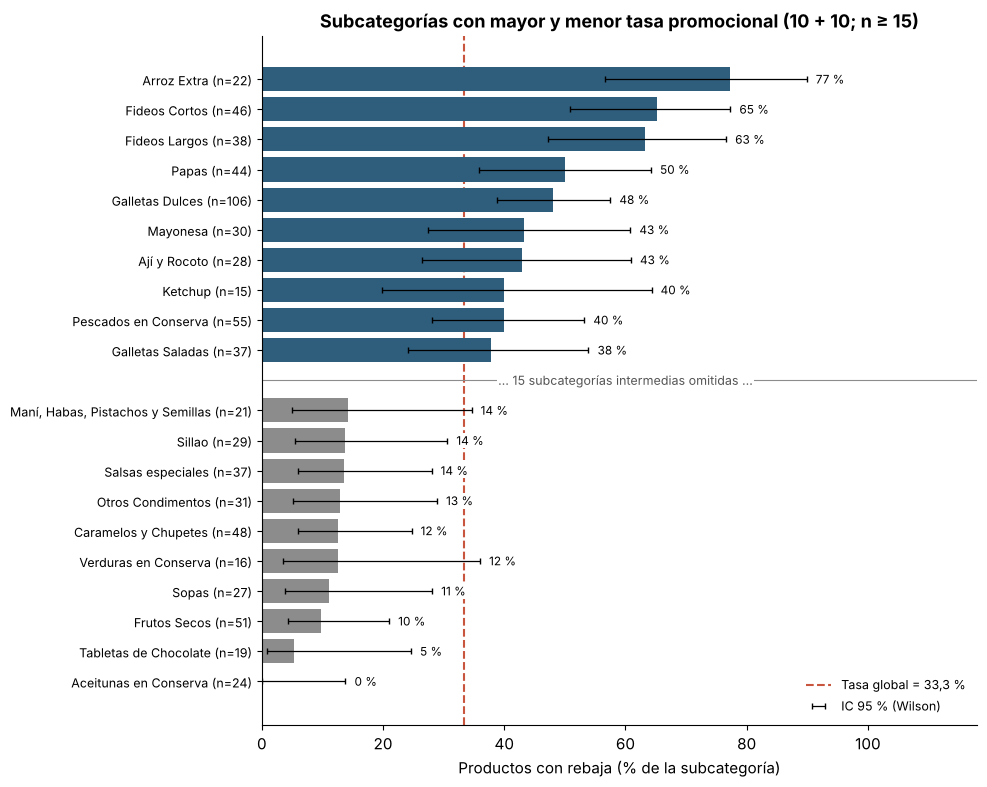

In [25]:
K = 10
sel = pd.concat([sub15_n3.tail(K), sub15_n3.head(K)]).sort_values("promo_rate")
n_omit = len(sub15_n3) - 2 * K
y = np.r_[np.arange(K), np.arange(K) + K + 1]           # hueco entre el bloque inferior y el superior
fig, ax = plt.subplots(figsize=(10, 8))
col = [AZUL if r.promo_rate >= B["promo_rate_global_pct"] else GRIS for _, r in sel.iterrows()]
ax.axvline(B["promo_rate_global_pct"], color=ROJO, ls="--", lw=1.5, zorder=1, label=f"Tasa global = {nf(B['promo_rate_global_pct'])} %")
ax.barh(y, sel["promo_rate"], color=col, zorder=2)
ax.errorbar(sel["promo_rate"], y, xerr=[sel["promo_rate"] - sel["ic95_inf"], sel["ic95_sup"] - sel["promo_rate"]],
            fmt="none", ecolor="black", elinewidth=0.9, capsize=2.5, zorder=3, label="IC 95 % (Wilson)")
for yi, (s, r) in zip(y, sel.iterrows()):
    ax.text(r.ic95_sup + 1.5, yi, f"{nf(r.promo_rate, 0)} %", va="center", fontsize=8.5,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5), zorder=5)
ax.axhline(K, color=GRIS, lw=0.8, ls="-", zorder=1)
ax.text(60, K, f"… {n_omit} subcategorías intermedias omitidas …", ha="center", va="center", fontsize=9, color="#555555",
        bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=5)
ax.set_yticks(y, [f"{s} (n={int(r.n)})" for s, r in sel.iterrows()])
ax.set_xlim(0, 118)
ax.tick_params(axis="y", labelsize=9)
ax.set_xlabel("Productos con rebaja (% de la subcategoría)")
ax.set_title(f"Subcategorías con mayor y menor tasa promocional ({K} + {K}; n ≥ {UMBRAL_GRUPO})")
ax.legend(frameon=True, facecolor="white", edgecolor="none", loc="lower right", fontsize=9)
ejes_coma(ax, "x")
plt.tight_layout()
top_s, bot_s = sub15_n3.iloc[0], sub15_n3.iloc[-1]
guardar_fig(fig, "fig11_promo_rate_subcategorias.png", "Subcategorías con mayor y menor tasa promocional (n ≥ 15)", "E",
            "E. ¿Qué subcategorías tienen más y menos rebajas?",
            f"Máx: {sub15_n3.index[0]} {nf(top_s['promo_rate'])} % (n = {int(top_s['n'])}); mín: {sub15_n3.index[-1]} "
            f"{nf(bot_s['promo_rate'])} % (n = {int(bot_s['n'])}); {n_omit} subcategorías intermedias omitidas; Packs Abarrotes excluido (sin nivel 3)",
            n=int(sel["n"].sum()))
M["subcategorias_n15"]["figura_n_omitidas"] = int(n_omit)
plt.show()

**Interpretación.**
- **Qué se observa:** al bajar al nivel de subcategoría el contraste se acentúa.
- **Cuánto:** 36 subcategorías cumplen n ≥ 15 (1243 productos, 86,5 % de la muestra); se excluye *Packs Abarrotes*, que no tiene nivel 3 y repite el grupo, y quedan 35. Las de mayor tasa son *Arroz Extra* (77,3 %; n = 22; IC 95 %: 56,6–89,9 %), *Fideos Cortos* (65,2 %; n = 46) y *Fideos Largos* (63,2 %; n = 38). Las de menor tasa son *Aceitunas en Conserva* (0 %; n = 24; IC 95 %: 0–13,8 %), *Tabletas de Chocolate* (5,3 %; n = 19) y *Frutos Secos* (9,8 %; n = 51). La figura muestra las 10 de mayor y las 10 de menor tasa; se omiten 15 subcategorías intermedias.
- **Por qué importa:** dentro de un mismo grupo hay subcategorías con comportamientos opuestos (p. ej., en *Chocolatería*: *Chocolates y Lentejas* 35,9 % vs. *Tabletas de Chocolate* 5,3 %), por lo que el grupo por sí solo no basta para describir la actividad promocional.
- **Relación con el objetivo:** permite focalizar el seguimiento de promociones en subcategorías concretas.

## F. Relaciones entre variables

**Pregunta F:** ¿Cómo se relacionan el precio regular y el actual? ¿Los productos más caros reciben descuentos porcentuales mayores? ¿Se diferencian los packs del resto? *(Asociaciones descriptivas; no implican causalidad.)*

In [26]:
rho_promo = promo[["current_price", "discount_pct"]].corr(method="spearman").iloc[0, 1]
rho_total = df[["current_price", "has_discount"]].corr(method="spearman").iloc[0, 1]
rho_total_reg = df[["regular_price", "has_discount"]].corr(method="spearman").iloc[0, 1]
rho_monto = promo[["regular_price", "discount_amount"]].corr(method="spearman").iloc[0, 1]
F = {"spearman_precio_vs_descuento_pct_promocionados": r2(rho_promo),
     "spearman_precio_vs_has_discount_total": r2(rho_total),
     "spearman_precio_regular_vs_has_discount_total": r2(rho_total_reg),
     "spearman_precio_regular_vs_descuento_soles_promocionados": r2(rho_monto)}
# Precio de productos con y sin rebaja
con_sin = df.groupby("has_discount").agg(n=("sku", "size"), precio_regular_mediano=("regular_price", "median"),
                                         precio_regular_q1=("regular_price", lambda s: s.quantile(0.25)),
                                         precio_regular_q3=("regular_price", lambda s: s.quantile(0.75)),
                                         precio_actual_mediano=("current_price", "median")).round(2)
con_sin.index = con_sin.index.map({0: "Sin rebaja", 1: "Con rebaja"})
con_sin.to_csv(TAB_DIR / "precio_con_vs_sin_rebaja.csv", encoding="utf-8")
F["precio_con_vs_sin_rebaja"] = {k: {kk: (int(vv) if kk == "n" else r2(vv)) for kk, vv in r.items()} for k, r in con_sin.iterrows()}
# Descuento mediano por cuartil de precio (entre promocionados) para leer la relación sin supuestos lineales
promo["cuartil_precio"] = pd.qcut(promo["current_price"], 4, labels=["Q1 (más baratos)", "Q2", "Q3", "Q4 (más caros)"])
desc_cuartil = promo.groupby("cuartil_precio", observed=True)["discount_pct"].agg(n="size", mediana="median").round(2)
desc_cuartil.to_csv(TAB_DIR / "descuento_por_cuartil_precio.csv", encoding="utf-8")
F["descuento_mediano_por_cuartil_precio"] = {str(k): {"n": int(r.n), "mediana_pct": r2(r.mediana)} for k, r in desc_cuartil.iterrows()}
print(f"Spearman precio actual vs discount_pct (promocionados, n={len(promo)}): {nf(rho_promo, 3)}")
print(f"Spearman precio actual vs has_discount (total, n={len(df)}): {nf(rho_total, 3)}")
print(f"Spearman precio regular vs has_discount (total, n={len(df)}): {nf(rho_total_reg, 3)}")
print(f"Spearman precio regular vs discount_amount en S/ (promocionados): {nf(rho_monto, 3)}")
display(con_sin)
desc_cuartil

Spearman precio actual vs discount_pct (promocionados, n=479): 0,025
Spearman precio actual vs has_discount (total, n=1437): -0,058
Spearman precio regular vs has_discount (total, n=1437): 0,048
Spearman precio regular vs discount_amount en S/ (promocionados): 0,812


,n,precio_regular_mediano,precio_regular_q1,precio_regular_q3,precio_actual_mediano
has_discount,,,,,
Sin rebaja,958,7.9,5.0,14.28,7.9
Con rebaja,479,9.0,5.4,15.00,7.9


,n,mediana
cuartil_precio,,
Q1 (más baratos),120,14.50
Q2,134,12.79
Q3,107,16.04
Q4 (más caros),118,15.34


Figura A8 guardada: reports/figures/fig12_precio_con_vs_sin_rebaja.png


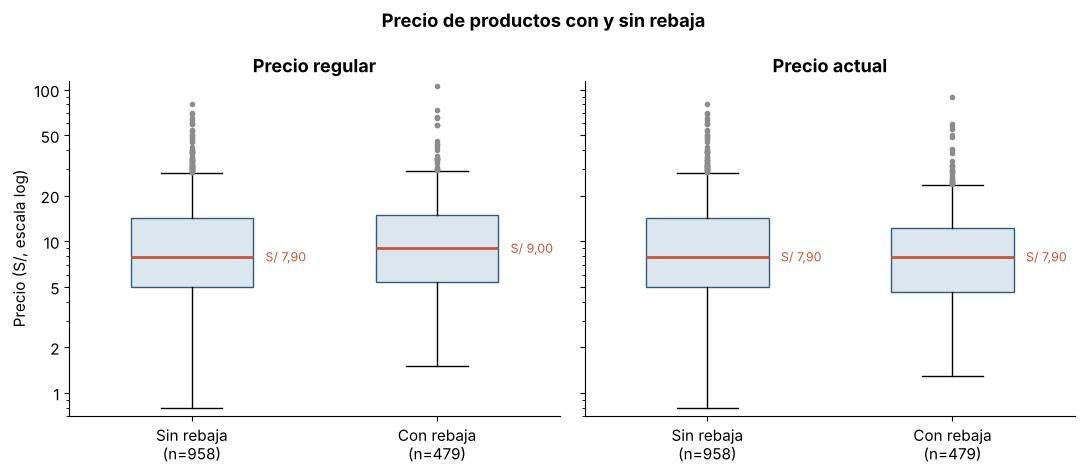

In [27]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, col, tit in [(a1, "regular_price", "Precio regular"), (a2, "current_price", "Precio actual")]:
    datos = [df.loc[df["has_discount"] == i, col] for i in [0, 1]]
    ax.boxplot(datos, tick_labels=[f"Sin rebaja\n(n={con_sin.loc['Sin rebaja', 'n']})", f"Con rebaja\n(n={con_sin.loc['Con rebaja', 'n']})"],
               widths=0.5, patch_artist=True, boxprops=dict(facecolor="#DCE6EE", color=AZUL), medianprops=dict(color=ROJO, lw=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS))
    for i, dd in enumerate(datos, start=1):
        ax.text(i + 0.3, dd.median(), f"S/ {nf(dd.median(), 2)}", va="center", fontsize=9, color=ROJO)
    ax.set_title(tit)
ejes_log_legibles(a1, "y")
a1.set_ylabel("Precio (S/, escala log)")
fig.suptitle("Precio de productos con y sin rebaja", fontweight="bold")
plt.tight_layout()
guardar_fig(fig, "fig12_precio_con_vs_sin_rebaja.png", "Precio regular y actual de productos con y sin rebaja", "F",
            "F. ¿Los productos con rebaja tienen un nivel de precio distinto?",
            f"Precio regular mediano S/ {nf(con_sin.loc['Con rebaja','precio_regular_mediano'], 2)} con rebaja vs "
            f"S/ {nf(con_sin.loc['Sin rebaja','precio_regular_mediano'], 2)} sin rebaja; Spearman ρ (precio actual vs rebaja) = {nf(rho_total, 2)}",
            n=len(df))
plt.show()

Figura 11 guardada: reports/figures/fig13_precio_vs_descuento.png


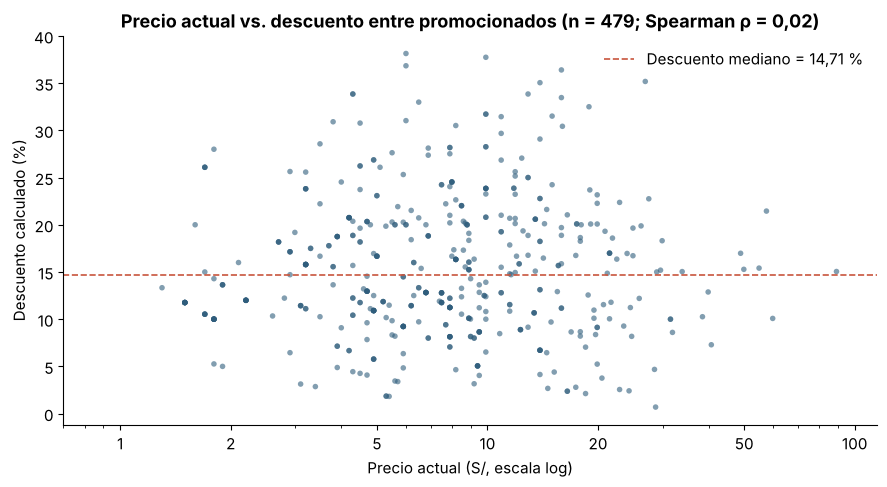

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(promo["current_price"], promo["discount_pct"], s=16, color=AZUL, alpha=0.6, edgecolor="none")
ejes_log_legibles(ax, "x")
ax.axhline(C["mediana_pct"], color=ROJO, ls="--", lw=1.2, label=f"Descuento mediano = {nf(C['mediana_pct'], 2)} %")
ax.set_xlabel("Precio actual (S/, escala log)")
ax.set_ylabel("Descuento calculado (%)")
ax.set_title(f"Precio actual vs. descuento entre promocionados (n = {len(promo)}; Spearman ρ = {nf(rho_promo, 2)})")
ax.legend(frameon=False, loc="upper right")
ejes_coma(ax, "y")
plt.tight_layout()
guardar_fig(fig, "fig13_precio_vs_descuento.png", "Precio actual vs. descuento (%) entre promocionados", "F",
            "F. ¿Los productos más caros tienen descuentos porcentuales mayores?",
            f"Spearman ρ = {nf(rho_promo, 2)}: sin asociación monótona entre precio y % de descuento", n=len(promo))
plt.show()

Figura A5 guardada: reports/figures/figA5_regular_vs_actual.png


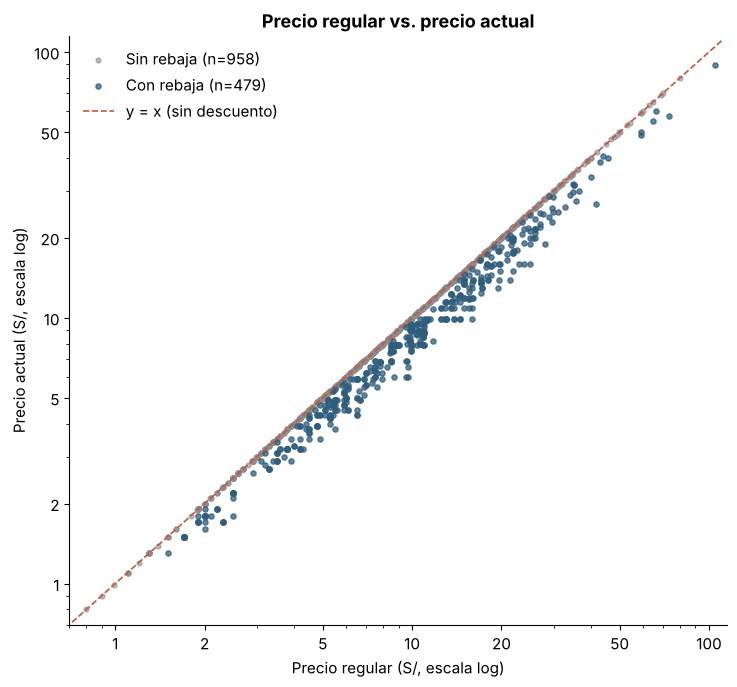

In [29]:
fig, ax = plt.subplots(figsize=(7.5, 7))
sin, con = df[df["has_discount"] == 0], df[df["has_discount"] == 1]
ax.scatter(sin["regular_price"], sin["current_price"], s=12, color=GRIS, alpha=0.6, label=f"Sin rebaja (n={len(sin)})")
ax.scatter(con["regular_price"], con["current_price"], s=14, color=AZUL, alpha=0.75, label=f"Con rebaja (n={len(con)})")
lim = df["regular_price"].max() * 1.05
ax.plot([0.5, lim], [0.5, lim], color=ROJO, ls="--", lw=1.2, label="y = x (sin descuento)")
ejes_log_legibles(ax, "xy")
ax.set_xlabel("Precio regular (S/, escala log)")
ax.set_ylabel("Precio actual (S/, escala log)")
ax.set_title("Precio regular vs. precio actual")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
F.update({"n_sobre_diagonal": int(len(sin)), "n_bajo_diagonal": int(len(con)),
          "n_actual_mayor_regular": int((df["current_price"] > df["regular_price"]).sum())})
guardar_fig(fig, "figA5_regular_vs_actual.png", "Precio regular vs. precio actual (validación de consistencia)", "F",
            "F. ¿Es consistente la relación entre precio regular y actual?",
            f"{F['n_sobre_diagonal']} productos sobre y = x, {F['n_bajo_diagonal']} por debajo, "
            f"{F['n_actual_mayor_regular']} por encima", n=len(df))
plt.show()

**Interpretación.**
- **Qué se observa:** el nivel de precio no se asocia ni con la presencia ni con la profundidad de la rebaja. En el diagrama de dispersión (Figura 11) no hay tendencia: a cualquier nivel de precio hay descuentos bajos, medios y altos.
- **Cuánto:** la correlación de Spearman entre precio actual y `discount_pct` entre promocionados es ρ = 0,02, y el descuento mediano por cuartil de precio se mantiene entre 12,79 % y 16,04 %. La presencia de rebaja tampoco se asocia al nivel de precio: ρ = −0,06 entre precio actual y `has_discount` (n = 1437). En la Figura A8 (Anexo A), el precio regular mediano es S/ 9,00 en los productos con rebaja y S/ 7,90 en los que no tienen rebaja, con rangos intercuartílicos muy superpuestos (ρ = 0,05 entre precio regular y `has_discount`); tras la rebaja, el precio actual mediano coincide en S/ 7,90. El ahorro en soles sí crece con el precio regular (ρ = 0,81), lo cual es esperable porque el mismo % aplicado a un precio mayor produce más soles.
- **Por qué importa:** la profundidad relativa de la rebaja **no está asociada** al nivel de precio; es una asociación descriptiva, no implica causalidad ni una regla de fijación de descuentos.
- **Relación con el objetivo:** describe cómo varía el descuento según el precio y justifica analizar `discount_pct` y `discount_amount` por separado.

*Validación (Figura A5, Anexo A):* 958 productos están sobre la diagonal y = x (sin rebaja), 479 por debajo y 0 por encima: el precio actual nunca supera al regular, lo que confirma la consistencia de la base sobre la que se calcula `discount_pct`.

In [30]:
# Packs: la categoría Packs Abarrotes frente a los packs ubicados en otras categorías y al resto
seg = np.select([df["category_group"] == "Packs Abarrotes", df["is_pack"] == 1],
                ["Packs Abarrotes (categoría)", "Pack en otra categoría"], "Resto de productos")
SEG = ["Packs Abarrotes (categoría)", "Pack en otra categoría", "Resto de productos"]
packs = (df.assign(segmento=seg).groupby("segmento")
           .agg(n=("sku", "size"), n_promo=("has_discount", "sum"), precio_mediano=("current_price", "median"),
                promo_rate=("has_discount", "mean")).reindex(SEG))
packs["promo_rate"] = (packs["promo_rate"] * 100).round(1)
packs = agregar_wilson(packs)
packs["descuento_mediano_promocionados"] = promo.assign(segmento=seg[df["has_discount"].to_numpy() == 1]).groupby("segmento")["discount_pct"].median().round(2)
packs.to_csv(TAB_DIR / "packs_segmentos.csv", encoding="utf-8")
k_p, n_p = int(packs.loc[SEG[0], "n_promo"]), int(packs.loc[SEG[0], "n"])
k_r, n_r = int(packs.loc[SEG[1:], "n_promo"].sum()), int(packs.loc[SEG[1:], "n"].sum())
F["packs"] = {"segmentos": {k: {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": r2(r.promo_rate),
                               "ic95_inf": r2(r.ic95_inf), "ic95_sup": r2(r.ic95_sup), "precio_mediano": r2(r.precio_mediano),
                               "descuento_mediano_pct": (None if pd.isna(r.descuento_mediano_promocionados) else r2(r.descuento_mediano_promocionados))}
                           for k, r in packs.iterrows()},
              "is_pack_total": {"n": int(df["is_pack"].sum()), "n_promo": int(df.loc[df["is_pack"] == 1, "has_discount"].sum())},
              "promo_rate_global_pct": B["promo_rate_global_pct"], "promo_rate_sin_packs_abarrotes_pct": B["promo_rate_sin_packs_pct"],
              "n_sin_packs_abarrotes": B["n_sin_packs"],
              "efecto_en_tasa_global_pp": r2(B["promo_rate_global_pct"] - B["promo_rate_sin_packs_pct"]),
              "prueba_packs_abarrotes_vs_resto": prueba_2x2(k_p, n_p, k_r, n_r),
              "nota": "is_pack coincide con category_group = 'Packs Abarrotes' en 60 de 64 casos; los 4 packs de otras categorías no tienen rebaja."}
M["relaciones"] = F
print("Packs Abarrotes vs. resto:", F["packs"]["prueba_packs_abarrotes_vs_resto"])
packs

Packs Abarrotes vs. resto: {'k1': 60, 'n1': 60, 'k2': 419, 'n2': 1377, 'tasa1_pct': 100.0, 'tasa2_pct': 30.43, 'chi2': 125.23, 'p_chi2': 4.54e-29, 'p_fisher': 1.74e-30}


,n,n_promo,precio_mediano,promo_rate,ic95_inf,ic95_sup,descuento_mediano_promocionados
segmento,,,,,,,
Packs Abarrotes (categoría),60,60,9.70,100.0,94.0,100.0,19.85
Pack en otra categoría,4,0,12.85,0.0,0.0,49.0,NaN
Resto de productos,1373,419,7.90,30.5,28.1,33.0,12.92


Figura 12 guardada: reports/figures/fig14_packs_abarrotes_vs_resto.png


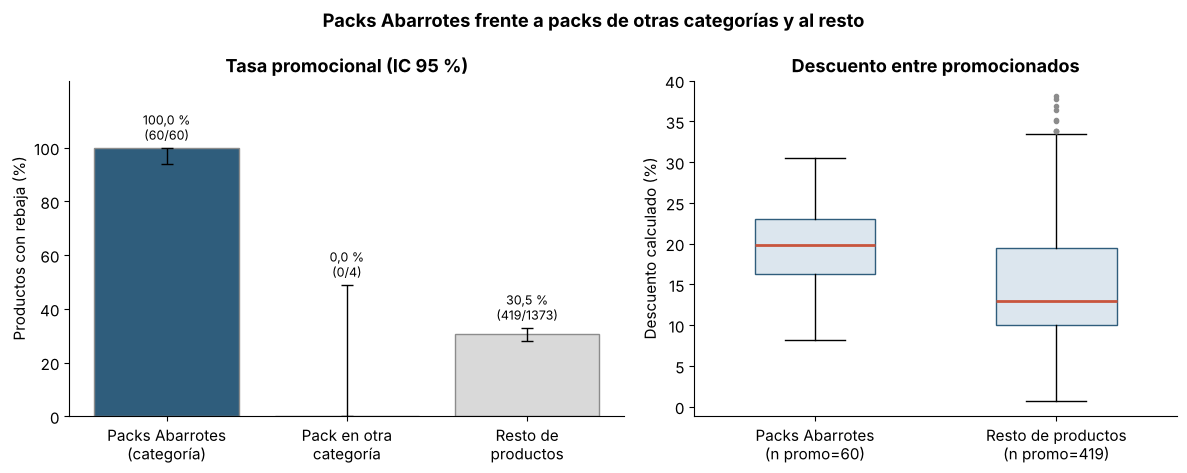

In [31]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
etq = ["Packs Abarrotes\n(categoría)", "Pack en otra\ncategoría", "Resto de\nproductos"]
x = np.arange(len(SEG))
a1.bar(x, packs["promo_rate"], color=[AZUL, GRIS, GRIS_CLARO], edgecolor=GRIS, zorder=2)
a1.errorbar(x, packs["promo_rate"], yerr=[packs["promo_rate"] - packs["ic95_inf"], packs["ic95_sup"] - packs["promo_rate"]],
            fmt="none", ecolor="black", elinewidth=1, capsize=4, zorder=3)
for i, (s, r) in enumerate(packs.iterrows()):
    a1.text(i, r.ic95_sup + 3, f"{nf(r.promo_rate)} %\n({int(r.n_promo)}/{int(r.n)})", ha="center", fontsize=9)
a1.set_xticks(x, etq)
a1.set_ylim(0, 125)
a1.set_yticks([0, 20, 40, 60, 80, 100])
a1.set_ylabel("Productos con rebaja (%)")
a1.set_title("Tasa promocional (IC 95 %)")
con_p = [promo.loc[promo["category_group"] == "Packs Abarrotes", "discount_pct"],
         promo.loc[(promo["category_group"] != "Packs Abarrotes") & (promo["is_pack"] == 0), "discount_pct"]]
a2.boxplot(con_p, tick_labels=[f"Packs Abarrotes\n(n promo={len(con_p[0])})", f"Resto de productos\n(n promo={len(con_p[1])})"],
           widths=0.5, patch_artist=True, boxprops=dict(facecolor="#DCE6EE", color=AZUL), medianprops=dict(color=ROJO, lw=2),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS))
a2.set_ylabel("Descuento calculado (%)")
a2.set_title("Descuento entre promocionados")
ejes_coma(a1, "y"); ejes_coma(a2, "y")
fig.suptitle("Packs Abarrotes frente a packs de otras categorías y al resto", fontweight="bold")
plt.tight_layout()
pk = F["packs"]["segmentos"]
guardar_fig(fig, "fig14_packs_abarrotes_vs_resto.png", "Packs Abarrotes frente a packs de otras categorías y al resto de productos", "F",
            "F. ¿La frecuencia de rebajas de los packs se asocia a la categoría o al formato?",
            f"Packs Abarrotes {nf(pk[SEG[0]]['promo_rate_pct'])} % ({pk[SEG[0]]['n_promo']}/{pk[SEG[0]]['n']}); packs en otras categorías "
            f"{pk[SEG[1]]['n_promo']}/{pk[SEG[1]]['n']}; resto {nf(pk[SEG[2]]['promo_rate_pct'])} %; descuento mediano "
            f"{nf(pk[SEG[0]]['descuento_mediano_pct'], 2)} % vs {nf(pk[SEG[2]]['descuento_mediano_pct'], 2)} %", n=len(df))
plt.show()

**Interpretación.**
- **Qué se observa:** la categoría *Packs Abarrotes* se publica con rebaja en el 100 % de sus 60 productos, mientras que los 4 packs ubicados en otras categorías no muestran rebaja (0/4).
- **Cuánto:** *Packs Abarrotes* 100 % (60/60; IC 95 %: 94,0–100 %) frente a 30,5 % en el resto de productos (419/1373); Fisher p < 0,001 frente a todos los demás productos. Entre promocionados, el descuento mediano es 19,85 % en *Packs Abarrotes* y 12,92 % en el resto (Figura 12, con el n de promocionados: 60 y 419). Sin la categoría, la tasa global baja de 33,3 % a 30,4 % (n = 1377), es decir, *Packs Abarrotes* la eleva en 2,9 p.p.
- **Por qué importa:** la alta frecuencia de rebajas se asocia a la **categoría** *Packs Abarrotes* del listado y no al **formato** pack en sí. Podría ser un artefacto de cómo el sitio arma esa categoría (por ejemplo, packs creados como oferta), lo que no puede verificarse con estos datos. `is_pack` es casi redundante con `category_group` (coinciden en 60 de 64 casos); se conserva solo porque permite este contraste.
- **Relación con el objetivo:** caracteriza un segmento con un comportamiento promocional distinto y explica cuánto influye en la tasa global.

## G. Anomalías y casos extremos

**Pregunta G:** ¿Qué productos presentan valores extremos o poco habituales que merecen revisión antes de interpretar los resultados?

In [32]:
cols_g = ["sku", "brand", "name", "category_group", "current_price", "regular_price", "discount_amount", "discount_pct"]
top_desc_pct = promo.sort_values("discount_pct", ascending=False).head(10)[cols_g]
top_desc_soles = promo.sort_values("discount_amount", ascending=False).head(10)[cols_g]
top_precio = df.sort_values("current_price", ascending=False).head(10)[cols_g]
desc_minimos = promo[promo["discount_pct"] < 3].sort_values("discount_pct")[cols_g]
outliers_por_grupo = df.groupby("category_group")["is_price_outlier"].agg(n_outliers="sum", n="size")
outliers_por_grupo["pct"] = (outliers_por_grupo["n_outliers"] / outliers_por_grupo["n"] * 100).round(1)
outliers_por_grupo = outliers_por_grupo.sort_values("n_outliers", ascending=False)
for nombre, t in [("top_descuento_pct", top_desc_pct), ("top_descuento_soles", top_desc_soles),
                  ("top_precio_actual", top_precio), ("descuentos_menores_3pct", desc_minimos)]:
    t.to_csv(TAB_DIR / f"anomalias_{nombre}.csv", index=False, encoding="utf-8")
outliers_por_grupo.to_csv(TAB_DIR / "outliers_precio_por_category_group.csv", encoding="utf-8")
G = {"top5_descuento_pct": [{"name": r["name"], "brand": r.brand, "discount_pct": r2(r.discount_pct)} for _, r in top_desc_pct.head(5).iterrows()],
     "top5_descuento_soles": [{"name": r["name"], "brand": r.brand, "discount_amount": r2(r.discount_amount)} for _, r in top_desc_soles.head(5).iterrows()],
     "top5_precio_actual": [{"name": r["name"], "brand": r.brand, "current_price": r2(r.current_price)} for _, r in top_precio.head(5).iterrows()],
     "n_descuentos_menores_3pct": int(len(desc_minimos)),
     "n_outliers_precio": int(df["is_price_outlier"].sum()),
     "outliers_precio_por_grupo": {g: int(r.n_outliers) for g, r in outliers_por_grupo.iterrows() if r.n_outliers > 0},
     "n_presentation_imputed": int(df["presentation_imputed"].sum())}
M["anomalias"] = G
print("Top 10 descuentos en %:"); display(top_desc_pct)
print("Top 10 descuentos en S/:"); display(top_desc_soles)

Top 10 descuentos en %:


,sku,brand,name,category_group,current_price,regular_price,discount_amount,discount_pct
158,19842,ONZA,Sal de Maras Fina ONZA Doypack 500g,"Salsas, Cremas y Condimentos",6.0,9.7,3.7,38.14
787,10020907,MUTTI,Passata de Tomate MUTTI Frasco 400g,"Fideos, Pastas y Salsas",9.9,15.9,6.0,37.74
1047,12400510,TAKIS,Tortillas de Maíz TAKIS Buckin' Ranch Bolsa 190g,Snacks y Piqueos,6.0,9.5,3.5,36.84
1084,12338940,BON O BON,Bombones de Chocolate BON O BON Supreme Caja 144g,Chocolatería,15.9,25.0,9.1,36.40
1060,12384045,SPLENDA,Endulzante SPLENDA Stevia Doypack 175g,Azúcar y Endulzantes,26.9,41.5,14.6,35.18
820,41859,WALIBI,Mayonesa WALIBI Doypack 1Kg,"Salsas, Cremas y Condimentos",13.9,21.4,7.5,35.05
579,10020910,MUTTI,Passata de Tomate MUTTI Frasco 700g,"Fideos, Pastas y Salsas",12.9,19.5,6.6,33.85
191,12101753,MOLITALIA,Fideo Tallarín MOLITALIA Bolsa 950g,"Fideos, Pastas y Salsas",4.3,6.5,2.2,33.85
469,12101754,MOLITALIA,Fideo Linguine MOLITALIA Bolsa 950g,"Fideos, Pastas y Salsas",4.3,6.5,2.2,33.85
1273,11907500,AMOR,Pasta Andina de Lenteja AMOR Fusilli Caja 227g,"Fideos, Pastas y Salsas",15.9,23.9,8.0,33.47


Top 10 descuentos en S/:


,sku,brand,name,category_group,current_price,regular_price,discount_amount,discount_pct
43,10216187,LAKANTO,Endulzante Natural LAKANTO Sweetener Golden Do...,Azúcar y Endulzantes,89.2,105.0,15.8,15.05
908,553,SPLENDA,Endulzante SPLENDA en Polvo Caja 200 Sobres,Azúcar y Endulzantes,57.5,73.2,15.7,21.45
1060,12384045,SPLENDA,Endulzante SPLENDA Stevia Doypack 175g,Azúcar y Endulzantes,26.9,41.5,14.6,35.18
1063,12382786,WONDERFUL,Pistachos WONDERFUL Jalapeño Bolsa 155g,Snacks y Piqueos,54.9,64.9,10.0,15.41
999,865,ACAVILLE,Aceite de Oliva ACAVILLE Extra Virgen Botella 1L,Aceite,48.9,58.9,10.0,16.98
1084,12338940,BON O BON,Bombones de Chocolate BON O BON Supreme Caja 144g,Chocolatería,15.9,25.0,9.1,36.40
186,12320292,NESTLÉ,Bombones Multipack NESTLÉ Bolsa 320g,Chocolatería,18.9,28.0,9.1,32.50
1062,12382787,WONDERFUL,Pistachos WONDERFUL Roast & Salt Bolsa 170g,Snacks y Piqueos,49.9,58.9,9.0,15.28
297,12568895,GRAN CHALAN,Pack Arroz Extra Gourmet Añejo GRAN CHALAN Bol...,Packs Abarrotes,27.5,35.6,8.1,22.75
1273,11907500,AMOR,Pasta Andina de Lenteja AMOR Fusilli Caja 227g,"Fideos, Pastas y Salsas",15.9,23.9,8.0,33.47


In [33]:
print("Top 10 precios actuales:"); display(top_precio)
print(f"Rebajas simbólicas (< 3 %): {len(desc_minimos)}"); display(desc_minimos)
print("Outliers de precio (IQR) por grupo:"); display(outliers_por_grupo)

Top 10 precios actuales:


,sku,brand,name,category_group,current_price,regular_price,discount_amount,discount_pct
43,10216187,LAKANTO,Endulzante Natural LAKANTO Sweetener Golden Do...,Azúcar y Endulzantes,89.2,105.0,15.8,15.05
587,54579,VALDEPORRES,Aceite de Oliva VALDEPORRES Gran Selección Bot...,Aceite,79.9,79.9,0.0,0.00
223,10708655,BELL'S,Aceite de Oliva BELL'S Extra Virgen Botella 2L,Aceite,69.9,69.9,0.0,0.00
756,10305534,FLORIDA,Filete de Atún FLORIDA en Agua Paquete 12un,Conservas,69.0,69.0,0.0,0.00
1211,12067976,NESTLÉ,Chocolate NESTLÉ Sublime Sonrisa Display 20un,Chocolatería,65.0,65.0,0.0,0.00
1228,12010280,BASCONTTI,Aceite de Oliva BASCONTTI Extra Virgen Botella 1L,Aceite,63.0,63.0,0.0,0.00
435,624,EL OLIVAR,Aceite de Oliva EL OLIVAR Extra Virgen Botella 1L,Aceite,59.9,59.9,0.0,0.00
1217,12067964,SANTOLIVO,Aceite de Oliva Extra Virgen OLI21 Botella 1L,Aceite,59.8,66.5,6.7,10.08
1028,12433210,LAKANTO,Endulzante Alulosa LAKANTO Golden Sabor Rubio ...,Azúcar y Endulzantes,59.0,59.0,0.0,0.00
1026,12433257,LAKANTO,Endulzante Alulosa LAKANTO Classic Natural Doy...,Azúcar y Endulzantes,59.0,59.0,0.0,0.00


Rebajas simbólicas (< 3 %): 12


,sku,brand,name,category_group,current_price,regular_price,discount_amount,discount_pct
1232,12005728,LA IBERICA,Chocolate LA IBÉRICA Milky Almendras sin Azúca...,Chocolatería,28.7,28.9,0.2,0.69
567,10109536,KIKKO,Salsa Ajoikion KIKKO Botella 350ml,"Salsas, Cremas y Condimentos",5.4,5.5,0.1,1.82
745,10705789,A1,Filete de Atún en Aceite Vegetal A1 Lata 140g,Conservas,5.3,5.4,0.1,1.85
537,10643172,A1,Filete de Atún A-1 en Agua y Sal Lata 140g,Conservas,5.3,5.4,0.1,1.85
367,10012683,BELL'S,Aceite Vegetal BELL'S Botella 3L,Aceite,18.5,18.9,0.4,2.12
160,13331,BELL'S,Arroz Superior BELL'S Bolsa 5Kg,Arroz,16.5,16.9,0.4,2.37
1363,11565332,GOYA,Sopa de Frejoles Negros GOYA Lata 425g,Conservas,16.5,16.9,0.4,2.37
896,1138,LA IBERICA,Chocolate LA IBÉRICA PASTILLAS DE LECHE De lec...,Chocolatería,24.3,24.9,0.6,2.41
383,23235,BELL'S,Arroz Integral BELL'S Bolsa 5Kg,Arroz,22.9,23.5,0.6,2.55
1329,11617650,BON O BON,Minis Bombones de Chocolate BON O BON Display ...,Chocolatería,14.6,15.0,0.4,2.67


Outliers de precio (IQR) por grupo:


,n_outliers,n,pct
category_group,,,
Aceite,27,58,46.6
Chocolatería,14,115,12.2
"Salsas, Cremas y Condimentos",9,305,3.0
Azúcar y Endulzantes,8,42,19.0
Galletas y Golosinas,5,254,2.0
Arroz,4,34,11.8
Snacks y Piqueos,4,228,1.8
Conservas,2,120,1.7
Packs Abarrotes,1,60,1.7


**Interpretación.**
- **Qué se observa:** los descuentos más altos (35–38 %) se dan en productos de precio bajo o medio de marcas variadas (sal de Maras ONZA, passata MUTTI, TAKIS, BON O BON, SPLENDA, WALIBI), mientras que los mayores ahorros en soles corresponden a productos caros (endulzantes, pistachos, aceite de oliva, packs). Los precios más altos (LAKANTO S/ 89,20; aceite de oliva VALDEPORRES S/ 79,90) son productos *premium* o presentaciones grandes.
- **Cuánto:** 6 productos superan el límite IQR de descuento (34,63 %); 74 productos son outliers de precio, concentrados en *Aceite* (27) y *Chocolatería* (14). Hay además 12 rebajas simbólicas (descuento < 3 %, ahorro de S/ 0,10 a S/ 0,60; 4 de ellas de BELL'S), que técnicamente cuentan como “promocionados” pero apenas cambian el precio.
- **Por qué importa:** ningún caso extremo es un error de captura (precios positivos y coherentes), por eso se conservan; pero las rebajas simbólicas recuerdan que `has_discount` mide presencia de rebaja, no su relevancia, y que la tasa debe leerse junto con la magnitud.
- **Relación con el objetivo:** delimita qué observaciones pueden influir en promedios y rankings, y refuerza el uso de medianas.

## Exportación de métricas e insights candidatos

Se consolidan en `reports/metrics.json` todas las cifras calculadas (incluidas las del preprocesamiento y sus tablas de calidad), el registro de figuras con su **numeración y título definitivos** y una propuesta de insights construida **exclusivamente** con esas cifras. Los textos generados (hallazgos de figuras e insights) usan coma decimal y la misma precisión que este notebook, para poder citarse literalmente.

In [34]:
# Métricas del preprocesamiento (notebook 02)
M["preprocesamiento"] = PRE

# Figuras del notebook 02 con la numeración definitiva y registro conjunto ordenado (cuerpo y anexo)
for nombre, meta in PRE["figuras_02"].items():
    num, etiqueta, ubic = info_fig(nombre)
    FIGURAS[nombre] = {"numero": num, "etiqueta": etiqueta, "titulo": meta["titulo"],
                       "titulo_completo": f"{etiqueta}. {meta['titulo']}", "ubicacion": ubic,
                       "archivo": f"reports/figures/{nombre}", "notebook": meta["notebook"], "seccion": "Preprocesamiento",
                       "pregunta": meta["pregunta"], "hallazgo_cifra": meta["hallazgo_cifra"], "n": meta["n"]}
orden_figs = sorted(FIG_CUERPO, key=FIG_CUERPO.get) + sorted(FIG_ANEXO, key=lambda f: int(FIG_ANEXO[f][1:]))
assert set(FIGURAS) == set(orden_figs), set(FIGURAS) ^ set(orden_figs)
assert all((FIG_DIR / f).exists() for f in orden_figs)
# pipeline.png es el diagrama generado por scripts/diagrama_pipeline.py (no lo produce un notebook)
assert sorted(p.name for p in FIG_DIR.glob("*.png") if p.name != "pipeline.png") == sorted(orden_figs), "Hay figuras huérfanas en reports/figures"
M["figures"] = {f: FIGURAS[f] for f in orden_figs}
M["figures_nota"] = ("Numeración idéntica a la del informe final: Figura 1 = reports/figures/pipeline.png (diagrama del "
                     "pipeline, generado por scripts/diagrama_pipeline.py); Figuras 2–12 en el cuerpo del informe y "
                     "Figuras A1–A8 en su Anexo A (figA1–figA5, fig08, fig09 y fig12). La presentación usa la misma "
                     "numeración. Los textos de hallazgo usan coma decimal.")
M["tablas_exportadas"] = sorted(p.name for p in TAB_DIR.glob("*.csv"))
pd.DataFrame([{k: v for k, v in FIGURAS[f].items()} for f in orden_figs]).set_index("etiqueta")[["titulo", "archivo", "ubicacion", "seccion", "n"]]

,titulo,archivo,ubicacion,seccion,n
etiqueta,,,,,
Figura 2,Porcentaje de valores faltantes por variable (...,reports/figures/fig01_valores_faltantes.png,cuerpo,Preprocesamiento,1438
Figura 3,Distribución del precio actual,reports/figures/fig02_distribucion_precio_actu...,cuerpo,A,1437
Figura 4,Precio actual por grupo de categoría,reports/figures/fig03_precio_por_category_grou...,cuerpo,A,1437
Figura 5,Precio por kg o por litro dentro de subcategor...,reports/figures/fig04_precio_unitario_subcateg...,cuerpo,A,897
Figura 6,Tasa promocional por grupo de categoría (IC 95 %),reports/figures/fig05_promo_rate_category_grou...,cuerpo,B,1437
Figura 7,Tasa promocional por marca (n ≥ 10): observada...,reports/figures/fig06_promo_rate_marcas.png,cuerpo,B,697
Figura 8,Distribución del descuento entre productos con...,reports/figures/fig07_distribucion_descuento.png,cuerpo,C,479
Figura 9,Intensidad promocional por grupo de categoría,reports/figures/fig10_intensidad_por_category_...,cuerpo,E,1437
Figura 10,Subcategorías con mayor y menor tasa promocion...,reports/figures/fig11_promo_rate_subcategorias...,cuerpo,E,724


In [35]:
pg_ = M["promo_rate_por_category_group"]; bl = M["marcas"]["bells"]
pkk = M["relaciones"]["packs"]; mc = M["magnitud_descuento_promocionados"]; it = M["promotion_intensity"]
md10 = M["marcas_n10"]["detalle"]
marcas_90 = {b: v for b, v in md10.items() if v["promo_rate_pct"] >= 90}
marcas_0 = {b: v for b, v in md10.items() if v["promo_rate_pct"] == 0}
bajo_global = {g: v for g, v in pg_.items() if v["promo_rate_pct"] < B["promo_rate_global_pct"]}
def g_txt(g):
    v = pg_[g]; return f"{g} {nf(v['promo_rate_pct'])} % (n = {v['n']})"
pb = bl["prueba_vs_resto"]; pp = pkk["prueba_packs_abarrotes_vs_resto"]; up = bl["precio_unitario_vs_resto"]
seg = pkk["segmentos"]

M["usuario_objetivo"] = ("Analista que monitorea precios y promociones publicados en el canal web de Abarrotes "
                         "(p. ej., en un equipo de pricing o category management, de inteligencia de mercado o de una marca "
                         "proveedora); seguimiento descriptivo de la oferta, sin evaluar ventas ni efectividad de promociones.")
M["insights_candidatos"] = [
    {"titulo": "1. La frecuencia promocional se concentra en pocos grupos y el promedio global la oculta",
     "evidencia": f"Tasa global {nf(B['promo_rate_global_pct'])} % ({B['n_promocionados']}/{B['n_total']}). "
                  f"{g_txt('Packs Abarrotes')}, {g_txt('Arroz')} y {g_txt('Fideos, Pastas y Salsas')}, frente a "
                  f"{g_txt('Comidas Instantáneas')}.",
     "interpretacion": "En la muestra extraída, la presencia de rebajas no es uniforme: se concentra en tres grupos y, dentro de ellos, en subcategorías específicas.",
     "implicacion": "Un promedio global de promociones oculta diferencias de más de 50 p.p. entre grupos.",
     "recomendacion": "Para el analista de monitoreo: reportar la tasa promocional por grupo de categoría y subcategoría (con n e IC 95 %) y no solo la global."},
    {"titulo": "2. El descuento típico es moderado (10–20 %) y no se asocia al nivel de precio",
     "evidencia": f"Entre {mc['n']} promocionados: mediana {nf(mc['mediana_pct'], 2)} %, "
                  f"IQR {nf(mc['q1_pct'], 2)}–{nf(mc['q3_pct'], 2)} %, máximo {nf(mc['max_pct'], 2)} %; "
                  f"{mc['n_mayor_30_pct']} productos ({nf(mc['pct_mayor_30'])} %) superan 30 %; "
                  f"nivel Medio = {nf(it['Medio']['pct_promocionados'])} % de los promocionados. "
                  f"Spearman ρ precio actual vs discount_pct = {nf(M['relaciones']['spearman_precio_vs_descuento_pct_promocionados'], 2)} (n = {mc['n']}); "
                  f"ρ precio regular vs ahorro en S/ = {nf(M['relaciones']['spearman_precio_regular_vs_descuento_soles_promocionados'], 2)}.",
     "interpretacion": "El estándar promocional observable es una rebaja de 10 % a 20 %; productos baratos y caros muestran rebajas porcentuales similares (sin asociación monótona con el precio), y el ahorro en soles crece con el precio por construcción.",
     "implicacion": "Un descuento superior a 20 % (≈ Q3) ya ubica a un producto en el cuarto superior; el porcentaje y el monto de descuento describen aspectos distintos de una promoción.",
     "recomendacion": "Para el analista de monitoreo: usar 10 % y 20 % como umbrales de referencia, revisar manualmente los descuentos > 30 % y las rebajas < 3 %, y comparar profundidad con discount_pct, no con el ahorro en soles."},
    {"titulo": "3. BELL'S: amplia presencia, rebajas poco frecuentes y menor precio publicado por kg o litro",
     "evidencia": f"BELL'S tiene {bl['n']} productos ({nf(bl['pct_muestra'])} % de la muestra) y tasa {nf(bl['promo_rate_pct'])} % "
                  f"({bl['n_promo']}/{bl['n']}) vs {nf(bl['promo_rate_resto_pct'])} % del resto (n = {bl['n_resto']}; "
                  f"Fisher {fmt_p(pb['p_fisher'])}); su tasa esperada por mezcla de grupos sería {nf(bl['promo_rate_esperada_pct'])} %; "
                  f"es menor que la del resto en {bl['grupos_bells_tasa_menor_que_resto']} de {bl['grupos_con_n_bells_5']} grupos donde tiene ≥ 5 productos; "
                  f"descuento mediano cuando rebaja {nf(bl['descuento_mediano_pct'], 2)} % vs {nf(bl['descuento_mediano_resto_pct'], 2)} % del resto. "
                  f"Su precio mediano por kg o litro es menor que el del resto en {up['n_subcategorias_bells_menor']} de {up['n_subcategorias']} subcategorías comparables.",
     "interpretacion": "En esta muestra, BELL'S aparece rara vez con rebaja, también dentro de los grupos comparables; la diferencia persiste al controlar por su mezcla de categorías. Su precio publicado por kg o litro suele ser menor que el de otras marcas de la misma subcategoría.",
     "implicacion": "La tasa promocional de una marca no basta para describir su nivel de precio publicado; los datos no permiten explicar el motivo de la diferencia.",
     "recomendacion": "Para el analista de monitoreo: reportar BELL'S por separado (tasa promocional y precio por kg o litro dentro de subcategoría) y verificar el patrón en varias fechas antes de describirlo como estable."},
    {"titulo": "4. Comportamiento polarizado entre marcas, entrelazado con la categoría",
     "evidencia": f"Entre {M['marcas_n10']['n_marcas']} marcas con n ≥ 10: {len(marcas_90)} con tasa ≥ 90 % "
                  f"({', '.join(f'{b} {nf(v['promo_rate_pct'])} % n = {v['n']}' for b, v in marcas_90.items())}) y "
                  f"{len(marcas_0)} con 0 % ({', '.join(f'{b} n = {v['n']}' for b, v in marcas_0.items())}). "
                  f"Con n entre 10 y 14, el IC 95 % tiene un ancho de {nf(M['marcas_n10']['ancho_ic95_pp_n10_14'][0])}–"
                  f"{nf(M['marcas_n10']['ancho_ic95_pp_n10_14'][1])} p.p.",
     "interpretacion": "La frecuencia promocional observable varía fuertemente entre marcas. Marca y categoría están entrelazadas (varias marcas con tasa ≥ 90 % publican sobre todo en Fideos, Pastas y Salsas), por lo que la diferencia no puede atribuirse solo a la marca.",
     "implicacion": "Los rankings de marcas deben acompañarse de n, intervalo de confianza y tasa esperada por mezcla de grupos.",
     "recomendacion": f"Para el analista de monitoreo: exigir n ≥ 10 y mostrar el IC antes de rankear marcas, y seguir en extracciones posteriores a las {len(marcas_90)} marcas con tasa ≥ 90 % y a las {len(marcas_0)} con 0 %."},
    {"titulo": "5. Packs Abarrotes: una categoría con rebaja en el 100 % de sus productos que eleva la tasa global",
     "evidencia": f"Packs Abarrotes: {seg['Packs Abarrotes (categoría)']['n_promo']}/{seg['Packs Abarrotes (categoría)']['n']} con rebaja, "
                  f"descuento mediano {nf(seg['Packs Abarrotes (categoría)']['descuento_mediano_pct'], 2)} % vs "
                  f"{nf(seg['Resto de productos']['descuento_mediano_pct'], 2)} % del resto; los packs de otras categorías: "
                  f"{seg['Pack en otra categoría']['n_promo']}/{seg['Pack en otra categoría']['n']}. "
                  f"Sin la categoría, la tasa global pasa de {nf(pkk['promo_rate_global_pct'])} % a {nf(pkk['promo_rate_sin_packs_abarrotes_pct'])} % "
                  f"(n = {pkk['n_sin_packs_abarrotes']}).",
     "interpretacion": "La alta frecuencia de rebajas se asocia a la categoría Packs Abarrotes del listado y no al formato pack: los packs ubicados en otras categorías no muestran rebaja. Podría reflejar cómo el sitio arma esa categoría, lo que no puede verificarse con estos datos.",
     "implicacion": f"Incluir Packs Abarrotes eleva la tasa global en {nf(pkk['efecto_en_tasa_global_pp'])} p.p.",
     "recomendacion": "Para el analista de monitoreo: reportar la tasa promocional con y sin la categoría Packs Abarrotes y analizar esa categoría como un segmento propio."},
]
M["insights_nota"] = ("Lista única de cinco insights, con los mismos títulos en el informe final (§9), el README (§8), la "
                      "presentación (diapositiva 16) y el guion (§3.F). La relación precio–descuento (Spearman) forma parte del insight 2.")

def a_nativo(o):
    # Convierte tipos numpy a tipos nativos de Python para JSON
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    raise TypeError(type(o))

with open(REP_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(M, f, indent=2, ensure_ascii=False, default=a_nativo)
print("metrics.json guardado con", len(M), "bloques y", len(M["figures"]), "figuras registradas")
for ins in M["insights_candidatos"]:
    print("\n•", ins["titulo"], "\n ", ins["evidencia"])

metrics.json guardado con 23 bloques y 19 figuras registradas

• 1. La frecuencia promocional se concentra en pocos grupos y el promedio global la oculta 
  Tasa global 33,3 % (479/1437). Packs Abarrotes 100,0 % (n = 60), Arroz 61,8 % (n = 34) y Fideos, Pastas y Salsas 52,9 % (n = 140), frente a Comidas Instantáneas 10,5 % (n = 38).

• 2. El descuento típico es moderado (10–20 %) y no se asocia al nivel de precio 
  Entre 479 promocionados: mediana 14,71 %, IQR 10,38–20,08 %, máximo 38,14 %; 21 productos (4,4 %) superan 30 %; nivel Medio = 52,0 % de los promocionados. Spearman ρ precio actual vs discount_pct = 0,02 (n = 479); ρ precio regular vs ahorro en S/ = 0,81.

• 3. BELL'S: amplia presencia, rebajas poco frecuentes y menor precio publicado por kg o litro 
  BELL'S tiene 184 productos (12,8 % de la muestra) y tasa 10,3 % (19/184) vs 36,7 % del resto (n = 1253; Fisher p < 0,001); su tasa esperada por mezcla de grupos sería 29,6 %; es menor que la del resto en 7 de 9 grupos donde ti

## Conclusiones del análisis

Los cinco insights son los mismos (con los mismos títulos) del informe final §9, el README §8 y la diapositiva 16:

1. **La frecuencia promocional se concentra en pocos grupos y el promedio global la oculta:** tasa global 33,3 % (479/1437), con *Packs Abarrotes* 100 % (n = 60), *Arroz* 61,8 % (n = 34) y *Fideos, Pastas y Salsas* 52,9 % (n = 140), frente a 10,5 % en *Comidas Instantáneas* (n = 38).
2. **El descuento típico es moderado (10–20 %) y no se asocia al nivel de precio:** mediana 14,71 %, IQR 10,38–20,08 %; el nivel *Medio* reúne el 52,0 % de los promocionados; Spearman ρ = 0,02 entre precio actual y `discount_pct`.
3. **BELL'S: amplia presencia, rebajas poco frecuentes y menor precio publicado por kg o litro:** 184 productos (12,8 %), tasa 10,3 % frente a 36,7 % del resto y 29,6 % esperada por su mezcla de grupos (menor en 7 de 9 grupos); precio por kg o litro menor que el del resto en 9 de 10 subcategorías comparables.
4. **Comportamiento polarizado entre marcas, entrelazado con la categoría:** entre 32 marcas con n ≥ 10, cinco alcanzan o superan el 90 % y tres tienen 0 %; varias de las primeras publican casi todo en *Fideos, Pastas y Salsas*.
5. **Packs Abarrotes: una categoría con rebaja en el 100 % de sus productos que eleva la tasa global:** 60/60 con rebaja frente a 0/4 packs de otras categorías; sin la categoría, la tasa global es 30,4 %.

**Precios (OE2):** distribución asimétrica a la derecha (mediana S/ 7,90 < media S/ 10,71); aun por kg o litro, la dispersión dentro de una subcategoría es amplia en las subcategorías heterogéneas (cociente Q3/Q1 entre 1,20 y 9,35).

**Limitaciones:** snapshot de una fecha; 30 de ~65 páginas del listado en orden de aparición (muestra no aleatoria, por lo que la composición por categoría y marca depende de ese orden); solo Abarrotes; sin datos de ventas. Los hallazgos describen la oferta publicada, no la demanda ni la efectividad de las promociones.
